# The movement between stopwatch ticks

Do defensive-front prospects organize approach, braking, direction change and recovery in a way that predicts rookie pressure performance? We test a finite movement-language adaptation of PerfectPower: sum over constrained possible histories rather than select a single noisy history. This experiment responds to the previous result's sensitivity to the definition of drill onset.

**Scope.** DE, DT, NT and OLB rookies with at least 30 eligible charted regular-season rush records. The target is each athlete's observed pressure-event frequency versus the mean model prediction over their actual NFL workload. This conditions on NFL snap geometry and game context; it is not an unconditional pre-draft production forecast or a causal training recommendation. The 2025 class has already been inspected. All transport results below are exploratory.


In [1]:
import os,sys,json,hashlib,tempfile,contextlib
from pathlib import Path
from IPython.display import display,Image
DATA=Path(os.environ.get('BDB_DATA_ROOT','/kaggle/input/nfl-big-data-bowl-2027')).resolve()
if not (DATA/'players.csv').exists():
    choices=list(Path('/kaggle/input').rglob('players.csv')) if Path('/kaggle/input').exists() else []
    if len(choices)!=1:raise FileNotFoundError('Attach the official competition dataset or set BDB_DATA_ROOT')
    DATA=choices[0].parent
WORK=Path(os.environ.get('BDB_WORK_ROOT',tempfile.mkdtemp(prefix='bdb_phase_'))).resolve();WORK.mkdir(exist_ok=True)
os.chdir(WORK);sys.path.insert(0,str(WORK))
MODULES={'analysis.py': '"""Combine-to-game research. No competition data are bundled or fabricated."""\nfrom pathlib import Path\nimport json, hashlib, argparse, platform\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.preprocessing import OneHotEncoder, StandardScaler\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor\n\nSEED=20271006\nBASE=[\'combine_height\',\'combine_weight\',\'ten_yd_split\',\'forty\',\'vertical\',\'broad_jump\',\'three_cone\',\'short_shuttle\']\nCONTEXT=[\'cushion\',\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\']\nCATS=[\'route_ran\',\'team_coverage_man_zone\',\'offense_formation\',\'in_motion_at_ball_snap\']\nMOTION=[\'entry_speed\',\'speed_retention\',\'exit_gain\',\'braking_impulse\',\'turn_angle\',\'curvature_energy\',\'jerk_rms\',\'signature_area\']\nCUT_ROUTES={\'OUT\',\'SLANT\',\'POST\',\'CORNER\',\'HITCH\'}\n\ndef movement(g,window=7):\n    """Largest interior heading change; fixed +/-0.5s event window, yards/seconds."""\n    g=g.sort_values(\'time\').copy()\n    t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    if len(t)<21 or np.any(np.diff(t)<=0): raise ValueError(\'short or duplicate/nonmonotone trajectory\')\n    dt=np.diff(t)\n    if not np.allclose(dt,.1,atol=.015): raise ValueError(\'irregular sampling; do not interpolate missing cuts\')\n    p=g[[\'x\',\'y\']].to_numpy(float)\n    if not np.isfinite(p).all(): raise ValueError(\'nonfinite coordinates\')\n    p=savgol_filter(p,window,3,axis=0)\n    v=np.gradient(p,.1,axis=0);a=np.gradient(v,.1,axis=0)\n    speed=np.linalg.norm(v,axis=1)\n    theta=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    k=np.arange(5,len(p)-5)\n    score=np.abs(theta[k+3]-theta[k-3]);score[(speed[k-3]<1)|(speed[k+3]<1)]=0\n    if score.max()<np.deg2rad(25): raise ValueError(\'no qualifying turn\')\n    c=int(k[np.flatnonzero(np.isclose(score,score.max(),rtol=0,atol=1e-10))[0]]);sl=slice(c-5,c+6)\n    turn=theta[c+3]-theta[c-3]\n    tangent=v[c-3]/speed[c-3];normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-5])@np.stack([tangent,normal],axis=1)\n    q[:,1]*=1 if turn>=0 else -1\n    # Antisymmetric level-two path signature, equal to signed area with closing chord.\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])\n    sp=speed[sl];at=np.gradient(sp,.1)\n    omega=np.gradient(theta,.1)[sl];curv=omega/np.maximum(sp,1)\n    out=dict(entry_speed=float(np.mean(sp[:3])),speed_retention=float(sp.min()/np.mean(sp[:3])),\n      exit_gain=float(np.mean(sp[-3:])-sp.min()),braking_impulse=float(np.trapezoid(np.maximum(-at,0),dx=.1)),\n      turn_angle=float(abs(turn)),curvature_energy=float(np.trapezoid(curv**2*sp,dx=.1)),\n      jerk_rms=float(np.sqrt(np.mean(np.gradient(a[sl],.1,axis=0)**2))),signature_area=float(area))\n    diag={\'t\':np.arange(-5,6)*.1,\'q\':q,\'speed\':sp,\'tangential_acceleration\':at,\'cut_index\':c}\n    return out,diag\n\ndef inventory(root):\n    """Stream all CSVs; retain observed counts/schema/hash, never treat descriptions as measured counts."""\n    rows=[]\n    for p in sorted(Path(root).glob(\'*.csv\')):\n        count=0;ids=set();years=set();cols=None\n        for c in pd.read_csv(p,chunksize=200000):\n            count+=len(c);cols=list(c.columns)\n            if \'nfl_id\' in c: ids.update(c.nfl_id.dropna().astype(int))\n            for key in (\'season\',\'draft_year\'):\n                if key in c:years.update(c[key].dropna().astype(int))\n        h=hashlib.sha256()\n        with p.open(\'rb\') as f:\n            for b in iter(lambda:f.read(8*1024*1024),b\'\'): h.update(b)\n        rows.append(dict(file=p.name,rows=count,unique_players=len(ids),years=sorted(years),columns=cols,sha256=h.hexdigest()))\n    return rows\n\ndef prepare(root,out):\n    root,out=Path(root),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(root/\'players.csv\');combine=pd.read_csv(root/\'combine_results.csv\');games=pd.read_csv(root/\'games.csv\')\n    for d,key in [(players,[\'nfl_id\']),(combine,[\'nfl_id\',\'draft_year\']),(games,[\'game_id\'])]:\n        if d.duplicated(key).any():raise ValueError(\'duplicate metadata join key\')\n    ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\']);pieces=[]\n    drill_counts={}\n    for c in pd.read_csv(root/\'combine_tracking.csv\',chunksize=200000):\n        c=c[c.nfl_id.isin(ids)&c.entity_type.eq(\'PLAYER\')&c.drill_type.eq(\'SKILL_DRILLS_WR\')]\n        pieces.append(c)\n        for name,n in c.drill_name.value_counts().items():drill_counts[name]=drill_counts.get(name,0)+int(n)\n    track=pd.concat(pieces,ignore_index=True);features=[];rejects=[]\n    for keys,g in track.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:\n            f,_=movement(g);features.append(dict(nfl_id=keys[0],draft_year=keys[1],event_id=keys[2],drill_name=g.drill_name.iloc[0],**f))\n        except ValueError as e:rejects.append(dict(event_id=keys[2],reason=str(e)))\n    f=pd.DataFrame(features)\n    if f.empty:raise ValueError(\'no qualifying WR turns; inspect drill availability before changing protocol\')\n    f.to_csv(out/\'attempt_features.csv\',index=False)\n    # Choose one homologous drill using Combine availability only, before NFL outcomes.\n    availability=f.groupby([\'drill_name\',\'draft_year\']).nfl_id.nunique().unstack(fill_value=0).reindex(columns=[2023,2024,2025],fill_value=0)\n    minimum=availability.min(axis=1);eligible=minimum[minimum>=5]\n    if eligible.empty:raise ValueError(\'no qualifying drill shared by >=5 WRs in every class; inspect availability\')\n    selected=sorted(eligible.index,key=lambda k:(-eligible[k],k))[0]\n    f=f[f.drill_name.eq(selected)]\n    agg=f.groupby([\'nfl_id\',\'draft_year\'])[MOTION].median().reset_index()\n    pp=pd.read_csv(root/\'player_play.csv\')\n    if pp.duplicated([\'game_id\',\'play_id\',\'nfl_id\']).any():raise ValueError(\'duplicate player-play key\')\n    pp=pp.merge(games[[\'game_id\',\'season\',\'season_type\']],on=\'game_id\',validate=\'many_to_one\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    d=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(CUT_ROUTES)&pp.play_nullified_by_penalty.eq(\'N\')].copy()\n    d=d[np.isfinite(d.separation_at_pass_forward)&(d.separation_at_pass_forward>=0)]\n    d=d.merge(combine,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(agg,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    # Each player must have >=20 measured routes. Threshold is frozen before labels are inspected.\n    n=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(n[n>=20].index)]\n    audit={\'status\':\'actual_data_prepared\',\'draft_class_players\':d.groupby(\'draft_year\').nfl_id.nunique().to_dict(),\n      \'draft_class_routes\':d.groupby(\'draft_year\').size().to_dict(),\'wr_roster_players\':len(ids),\'qualifying_attempts\':len(f),\n      \'selected_drill\':selected,\'drill_player_availability\':availability.to_dict(),\'excluded_attempts\':rejects,\'drill_frame_counts\':drill_counts,\'target_only_fraction\':float(d.target.mean()) if len(d) else None,\n      \'game_tracking_use\':\'Primary outcome uses official separation; game trajectory replication remains secondary and unrun.\'}\n    temp=out/\'private_analysis_rows.csv.tmp\';d.to_csv(temp,index=False);temp.replace(out/\'private_analysis_rows.csv\');\n    if len(pd.read_csv(out/\'private_analysis_rows.csv\'))!=len(d):raise ValueError(\'analysis CSV roundtrip row mismatch\')\n    d.to_pickle(out/\'private_analysis_rows.pkl\');(out/\'population_audit.json\').write_text(json.dumps(audit,indent=2))\n    return d,f,audit\n\ndef model(d,nums,kind,alpha=10):\n    numeric=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n    cats=Pipeline([(\'impute\',SimpleImputer(strategy=\'most_frequent\')),(\'onehot\',OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))])\n    pre=ColumnTransformer([(\'numeric\',numeric,nums),(\'category\',cats,CATS)])\n    reg=Ridge(alpha=alpha) if kind==\'ridge\' else RandomForestRegressor(n_estimators=200,min_samples_leaf=20,max_depth=6,max_features=.8,random_state=SEED,n_jobs=2)\n    return Pipeline([(\'pre\',pre),(\'reg\',reg)])\n\ndef weights(d):return 1/d.groupby(\'nfl_id\').nfl_id.transform(\'size\').to_numpy()\ndef score(d,p):return float(np.average((d.separation_at_pass_forward.to_numpy()-p)**2,weights=weights(d)))\n\ndef compare(d,out):\n    """Player-disjoint, rookie-season-disjoint validation and locked 2025 test."""\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);d=d.copy()\n    if not (d.season==d.draft_year).all():raise ValueError(\'rookie seasons required\')\n    for col in MOTION:\n        d[col+\'_mass\']=d[col]*d.combine_weight/200\n        d[col+\'_man\']=d[col]*d.team_coverage_man_zone.eq(\'MAN_COVERAGE\').astype(int)\n    families={\'conventional\':BASE+CONTEXT,\'tracking\':BASE+CONTEXT+MOTION,\n      \'physical_context_interactions\':BASE+CONTEXT+MOTION+[c+s for c in MOTION for s in (\'_mass\',\'_man\')],\n      \'scouting_reference\':BASE+CONTEXT+[\'ngs_college_production_score\']}\n    a,b,t=[d[d.draft_year.eq(y)] for y in (2023,2024,2025)]\n    if min(x.nfl_id.nunique() for x in (a,b,t))<10:raise ValueError(\'fewer than ten WRs in a class; insufficient locked-cohort study\')\n    assert not(set(a.nfl_id)&set(b.nfl_id) or set(a.nfl_id)&set(t.nfl_id) or set(b.nfl_id)&set(t.nfl_id))\n    dev=pd.concat([a,b]);results=[];pred={};selections={}\n    for kind in (\'ridge\',\'forest\'):\n      for family,nums in families.items():\n        options=(1,10,100) if kind==\'ridge\' else (10,)\n        vals=[]\n        for alpha in options:\n            m=model(a,nums,kind,alpha);m.fit(a,a.separation_at_pass_forward,reg__sample_weight=weights(a));vals.append((score(b,m.predict(b)),alpha))\n        _,alpha=min(vals);selections[kind+\'_\'+family]={\'alpha\':alpha,\'validation_mse\':min(vals)[0]}\n        m=model(dev,nums,kind,alpha);m.fit(dev,dev.separation_at_pass_forward,reg__sample_weight=weights(dev));p=m.predict(t)\n        name=kind+\'_\'+family;pred[name]=p\n        results.append({\'model\':name,\'test_player_balanced_mse\':score(t,p),\'test_rmse_yards\':score(t,p)**.5,\'validation_mse\':min(vals)[0]})\n    # Primary contrast is ridge tracking vs ridge conventional. Others exploratory.\n    losses=pd.DataFrame({\'nfl_id\':t.nfl_id,\'baseline\':(t.separation_at_pass_forward-pred[\'ridge_conventional\'])**2,\'tracking\':(t.separation_at_pass_forward-pred[\'ridge_tracking\'])**2}).groupby(\'nfl_id\').mean()\n    delta=(losses.baseline-losses.tracking).to_numpy();rng=np.random.default_rng(SEED)\n    boots=np.mean(rng.choice(delta,(5000,len(delta)),replace=True),axis=1)\n    report={\'status\':\'actual_data_completed\',\'primary_delta_mse_yards_squared\':float(delta.mean()),\'player_bootstrap_ci95\':np.quantile(boots,[.025,.975]).tolist(),\n      \'test_players\':len(delta),\'test_routes\':len(t),\'results\':results,\'selection\':selections,\n      \'interpretation\':\'positive delta favors motion; CI crossing zero is inconclusive; cohort-generalization requires more years\',\n      \'selection_warning\':\'Exploratory models cannot replace the preregistered primary contrast after observing test labels.\'}\n    pd.DataFrame(results).to_csv(out/\'model_comparisons.csv\',index=False)\n    (out/\'experiment_results.json\').write_text(json.dumps(report,indent=2))\n    pp=t[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in pred.items():pp[k]=v\n    pp.to_csv(out/\'private_test_predictions.csv\',index=False)\n    return report\n\ndef plot_motion(diag,path,label):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    plt.rcParams.update({\'font.family\':\'DejaVu Sans\',\'text.color\':\'#e6edf6\',\'axes.labelcolor\':\'#c2cfde\',\'xtick.color\':\'#8aa0b6\',\'ytick.color\':\'#8aa0b6\',\'axes.edgecolor\':\'#304359\',\'axes.facecolor\':\'#102236\',\'figure.facecolor\':\'#071421\'})\n    fig,ax=plt.subplots(1,3,figsize=(16,5),layout=\'constrained\');q=diag[\'q\'];t=diag[\'t\'];s=diag[\'speed\'];a=diag[\'tangential_acceleration\']\n    sc=ax[0].scatter(q[:,0],q[:,1],c=s,cmap=\'plasma\',s=80,zorder=3);ax[0].plot(q[:,0],q[:,1],color=\'#39dbbd\',alpha=.8);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Along entry direction · yards\',ylabel=\'Across entry direction · yards\',title=\'THE SHAPE OF THE CUT\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\',shrink=.7)\n    ax[1].plot(t,s,lw=3,color=\'#39dbbd\');ax[1].axvline(0,color=\'#efb455\',ls=\':\');ax[1].set(xlabel=\'Seconds from largest turn\',ylabel=\'Speed · yd/s\',title=\'BRAKE → TURN → RECOVER\')\n    ax[2].plot(s,a,lw=2,color=\'#efb455\');ax[2].scatter(s,a,c=t,cmap=\'cool\',s=40);ax[2].axhline(0,color=\'#304359\');ax[2].set(xlabel=\'Speed · yd/s\',ylabel=\'Tangential acceleration · yd/s²\',title=\'MOVEMENT PHASE PORTRAIT\')\n    for z in ax:z.grid(alpha=.12)\n    fig.suptitle(label,fontsize=17,fontweight=\'bold\');fig.savefig(path,dpi=150);plt.close(fig)\n\ndef run(root,out):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    (out/\'inventory.json\').write_text(json.dumps(inventory(root),indent=2))\n    d,f,audit=prepare(root,out);report=compare(d,out)\n    # Selected example by sorted ID, independent of outcomes. Read only WR tracking rows.\n    chosen=f.sort_values([\'nfl_id\',\'event_id\']).iloc[0];parts=[]\n    for c in pd.read_csv(Path(root)/\'combine_tracking.csv\',chunksize=200000):parts.append(c[c.event_id.eq(chosen.event_id)&c.entity_type.eq(\'PLAYER\')])\n    g=pd.concat(parts);_,diag=movement(g);plot_motion(diag,out/\'actual_combine_geometry.png\',\'Observed Combine trajectory · selected without NFL outcomes\')\n    (out/\'actual_combine_geometry.html\').write_text(motion_html(diag,\'Observed Combine attempt · selected independently of NFL outcomes\'))\n    return report\n\n\ndef game_transfer(root,d,out):\n    """Secondary descriptive mechanics replication; game motion never a prospect predictor."""\n    out=Path(out);pieces=[];ids=set(d.nfl_id)\n    keys=d[[\'game_id\',\'play_id\',\'nfl_id\']].drop_duplicates()\n    for year in (2023,2024,2025):\n        p=Path(root)/f\'game_tracking_{year}.csv\';parts=[]\n        for c in pd.read_csv(p,chunksize=200000):\n            c=c[c.nfl_id.isin(ids)].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],how=\'inner\',validate=\'many_to_one\');parts.append(c)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\']):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if snap.empty or release.empty:continue\n            g=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:\n                f,_=movement(g);pieces.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            except ValueError:continue\n    pd.DataFrame(pieces).to_csv(out/\'private_game_motion.csv\',index=False)\n    return {\'status\':\'descriptive_only\',\'qualifying_game_turns\':len(pieces),\'note\':\'No 22-player coverage reconstruction. Game movement is outcome-side diagnostic, never a pre-draft predictor.\'}\n\ndef motion_html(diag,label):\n    """Offline SVG animation of measured samples, not a generated football replay."""\n    import html\n    data=json.dumps({k:diag[k].tolist() for k in (\'t\',\'q\',\'speed\',\'tangential_acceleration\')})\n    template=\'\'\'<!doctype html><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>Inside the cut</title><style>\nbody{background:#071421;color:#e6edf6;font:17px system-ui;margin:0;padding:4vw}main{max-width:1000px;margin:auto}.tag{color:#39dbbd;font-size:12px;letter-spacing:2px}h1{font-size:clamp(28px,5vw,52px)}.layout{display:grid;grid-template-columns:2fr 1fr;gap:24px}svg{background:#102236;width:100%;border-radius:20px}button{background:#39dbbd;color:#071421;border:0;border-radius:9px;padding:12px 22px;font-weight:700}input{width:100%;accent-color:#39dbbd}small{color:#9cafc3}strong{font-size:40px;display:block}.metric{margin:22px 0}@media(max-width:650px){.layout{grid-template-columns:1fr}} </style>\n<main><div class="tag">MOVEMENT LAB · FRAME BY FRAME</div><h1>Inside the cut.</h1><p>LABEL</p><div class="layout"><svg id="field" viewBox="0 0 600 400" role="img" aria-label="Canonical trajectory in yards"><g id="grid"></g><path id="path" fill="none" stroke="#39dbbd" stroke-width="3"/><g id="samples"></g><circle id="player" r="12" fill="#efb455" stroke="#071421" stroke-width="4"/><text x="22" y="380" fill="#9cafc3" font-size="14">Canonical entry frame · yards</text></svg><aside><div class="metric">Time from detected turn<strong id="time"></strong><small>seconds</small></div><div class="metric">Speed<strong id="speed"></strong><small>yards / second</small></div><div class="metric">Braking / reacceleration<strong id="acc"></strong><small>yards / second²</small></div></aside></div><p><button id="play">Play movement</button> <small>Eleven observed samples; interpolation animates the marker only.</small></p><input id="frame" type="range" min="0" max="10" step=".01" value="0" aria-label="Inspect tracking moment"><p><small>The line is the sampled path. Color indicates speed. A positive acceleration value means the athlete is regaining speed. The dot does not represent a defender or a missing NFL player.</small></p></main>\n<script>const D=DATA;const ns=\'http://www.w3.org/2000/svg\';const xs=D.q.map(p=>p[0]),ys=D.q.map(p=>p[1]);let xmin=Math.min(...xs),xmax=Math.max(...xs),ymin=Math.min(...ys),ymax=Math.max(...ys);const scale=Math.min(500/Math.max(xmax-xmin,.2),280/Math.max(ymax-ymin,.2));const P=D.q.map(p=>[50+(p[0]-xmin)*scale,330-(p[1]-ymin)*scale]);function node(tag,attrs,parent){let e=document.createElementNS(ns,tag);for(let k in attrs)e.setAttribute(k,attrs[k]);parent.appendChild(e);return e}for(let x=Math.floor(xmin);x<=xmax;x++){const z=50+(x-xmin)*scale;node(\'line\',{x1:z,y1:20,x2:z,y2:350,stroke:\'#233c51\'},document.querySelector(\'#grid\'));const t=node(\'text\',{x:z,y:365,fill:\'#9cafc3\',\'font-size\':12},document.querySelector(\'#grid\'));t.textContent=x;}document.querySelector(\'#path\').setAttribute(\'d\',P.map((p,i)=>(i?\'L\':\'M\')+p.join(\',\')).join(\' \'));let low=Math.min(...D.speed),high=Math.max(...D.speed);P.forEach((p,i)=>node(\'circle\',{cx:p[0],cy:p[1],r:5,fill:`hsl(${180-140*(D.speed[i]-low)/Math.max(high-low,.01)} 75% 60%)`},document.querySelector(\'#samples\')));let f=document.querySelector(\'#frame\'),playing=false,last=0;function show(){let z=+f.value,i=Math.min(9,Math.floor(z)),a=z-i;let p=P[i].map((v,k)=>v+(P[i+1][k]-v)*a);document.querySelector(\'#player\').setAttribute(\'cx\',p[0]);document.querySelector(\'#player\').setAttribute(\'cy\',p[1]);for(let [id,key] of [[\'time\',\'t\'],[\'speed\',\'speed\'],[\'acc\',\'tangential_acceleration\']])document.querySelector(\'#\'+id).textContent=(D[key][i]+(D[key][i+1]-D[key][i])*a).toFixed(2)}f.oninput=()=>{playing=false;document.querySelector(\'#play\').textContent=\'Play movement\';show()};document.querySelector(\'#play\').onclick=()=>{playing=!playing;if(+f.value>=10)f.value=0;document.querySelector(\'#play\').textContent=playing?\'Pause\':\'Play movement\';last=performance.now()};function tick(now){if(playing){f.value=Math.min(10,+f.value+(now-last)/300);show();if(+f.value>=10){playing=false;document.querySelector(\'#play\').textContent=\'Replay movement\'}}last=now;requestAnimationFrame(tick)}show();requestAnimationFrame(tick);</script>\'\'\'\n    return template.replace(\'LABEL\',html.escape(label)).replace(\'DATA\',data)\n\nif __name__==\'__main__\':\n    ap=argparse.ArgumentParser();ap.add_argument(\'--data\',required=True);ap.add_argument(\'--out\',default=\'private_results\');args=ap.parse_args();print(json.dumps(run(args.data,args.out),indent=2))\n', 'repo_predict.py': '"""Prospect-balanced compression and development-only model selection.\n\n2025 was already inspected before this push; its results are exploratory.\n"""\nfrom pathlib import Path\nimport json,time\nimport numpy as np,pandas as pd\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nfrom sklearn.model_selection import StratifiedGroupKFold\nimport analysis as A\n\nPHYS=A.BASE+[\'hand_size\',\'arm_length\',\'wing_span\',\'bench_reps\',\'ngs_athleticism_score\',\'ngs_college_production_score\',\'ngs_final_score\']\nNUM=A.CONTEXT+[\'quarter\']\nCAT=A.CATS+[\'team_coverage_type\',\'receiver_alignment\',\'team_abbr\',\'defense_team\']\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':1,\'k\':4},{\'reg\':\'ridge\',\'alpha\':10,\'k\':4},{\'reg\':\'ridge\',\'alpha\':100,\'k\':8},{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':8}]\n\nclass ProspectEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,motion=(),k=4):self.motion=motion;self.k=k\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_player_ids_=set(players.nfl_id)\n        self.phys=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.phys.fit(players[PHYS])\n        self.num=Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())]);self.num.fit(x[NUM])\n        self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);self.cat.fit(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))\n        if self.motion:\n            m=players[list(self.motion)].to_numpy(float);self.lo=np.nanquantile(m,.01,axis=0);self.hi=np.nanquantile(m,.99,axis=0)\n            self.lo=np.nan_to_num(self.lo);self.hi=np.nan_to_num(self.hi)\n            self.mi=SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True);m=self.mi.fit_transform(np.clip(m,self.lo,self.hi));self.ms=StandardScaler();m=self.ms.fit_transform(m)\n            self.pca=PCA(n_components=min(self.k,len(players)-1,m.shape[1]),svd_solver=\'full\');self.pca.fit(m)\n        return self\n    def transform(self,x):\n        blocks=[self.phys.transform(x[PHYS]),self.num.transform(x[NUM]),self.cat.transform(x[CAT].astype(str).where(x[CAT].notna(),\'MISSING\'))]\n        if self.motion:\n            m=np.clip(x[list(self.motion)].to_numpy(float),self.lo,self.hi);blocks.append(self.pca.transform(self.ms.transform(self.mi.transform(m))))\n        return np.column_stack(blocks)\n\ndef columns(panel,family):\n    cols=[c for c in panel if c.startswith(\'motion__\')]\n    if family==\'baseline\':return ()\n    if family==\'summary\':return tuple(c for c in cols if c.split(\'__\')[-1] in A.MOTION)\n    if family==\'signature\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith(\'sig_\'))\n    if family==\'dynamics\':return tuple(c for c in cols if c.split(\'__\')[-1].startswith((\'memory_\',\'hankel_\',\'profile_\')))\n    if family==\'all\':return tuple(cols)\n    raise ValueError(\'family\')\n\ndef make(motion,config):\n    enc=ProspectEncoder(motion,config[\'k\'])\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    return Pipeline([(\'enc\',enc),(\'reg\',reg)])\n\ndef fit_predict(train,test,motion,config):\n    if set(train.nfl_id)&set(test.nfl_id):raise ValueError(\'player overlap\')\n    m=make(motion,config);m.fit(train,train.separation_at_pass_forward,reg__sample_weight=A.weights(train));return m,m.predict(test)\n\ndef prepare(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);data_root=Path(data_root) if data_root else root/\'data\';analysis_out=Path(analysis_out) if analysis_out else root/\'private_results\';d=pd.read_pickle(analysis_out/\'private_analysis_rows.pkl\') if (analysis_out/\'private_analysis_rows.pkl\').exists() else pd.read_csv(analysis_out/\'private_analysis_rows.csv\');panel=pd.read_csv(out/\'private_motion_panel.csv\');d=d.drop(columns=A.MOTION).merge(panel,on=\'nfl_id\',validate=\'many_to_one\')\n    g=pd.read_csv(data_root/\'games.csv\').set_index(\'game_id\');home=d.game_id.map(g.home_team_abbr);away=d.game_id.map(g.visitor_team_abbr);d[\'defense_team\']=np.where(home==d.team_abbr,away,home)\n    if d.nfl_id.nunique()!=64 or len(d)!=7348:raise ValueError(\'frozen population changed\')\n    return d,panel\n\ndef bootstrap(test,p0,p1):\n    x=pd.DataFrame({\'id\':test.nfl_id,\'delta\':(test.separation_at_pass_forward-p0)**2-(test.separation_at_pass_forward-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED);boots=rng.choice(x,(5000,len(x)),replace=True).mean(axis=1)\n    return {\'delta_mse\':float(x.mean()),\'ci95\':np.quantile(boots,[.025,.975]).tolist(),\'players\':len(x)}\n\ndef cohort_trial(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);train=d[d.draft_year.eq(2023)];val=d[d.draft_year.eq(2024)];dev=d[d.draft_year.isin([2023,2024])];test=d[d.draft_year.eq(2025)]\n    bank=[];selected={};preds={};start=time.perf_counter()\n    for family in [\'baseline\',\'summary\',\'signature\',\'dynamics\',\'all\']:\n        cc=columns(panel,family);candidates=[]\n        for i,config in enumerate(CONFIGS):\n            m,p=fit_predict(train,val,cc,config);v=A.score(val,p);candidates.append((v,i));bank.append({\'family\':family,\'config\':i,\'validation_mse\':v});print(\'Validation\',family,i,round(v,6),flush=True)\n        v,i=min(candidates);m,p=fit_predict(dev,test,cc,CONFIGS[i]);preds[family]=p;selected[family]={\'config\':CONFIGS[i],\'config_index\':i,\'validation_mse\':v,\'test_mse\':A.score(test,p),\'test_rmse_yards\':A.score(test,p)**.5,\'motion_input_columns\':len(cc),\'motion_latent_dimension\':m.named_steps[\'enc\'].pca.n_components_ if cc else 0}\n    for family in [\'summary\',\'signature\',\'dynamics\',\'all\']:selected[family][\'paired_vs_strong_conventional\']=bootstrap(test,preds[\'baseline\'],preds[family])\n    original=pd.read_csv((Path(analysis_out) if analysis_out else root/\'private_results\')/\'private_test_predictions.csv\');q=test[[\'nfl_id\',\'game_id\',\'play_id\']].merge(original,on=[\'nfl_id\',\'game_id\',\'play_id\'],validate=\'one_to_one\')\n    old=q.forest_conventional.to_numpy();selected[\'all\'][\'paired_vs_original_forest\']=bootstrap(test,old,preds[\'all\'])\n    result={\'status\':\'exploratory_actual_data\',\'test_previously_inspected\':True,\'selection\':\'2023 train; 2024 tune; refit 2023+2024; 2025 exploratory transport\',\'primary_new_family\':\'all\',\'selected\':selected,\'validation_bank\':bank,\'same_candidates_per_family\':len(CONFIGS),\'test_players\':test.nfl_id.nunique(),\'test_routes\':len(test),\'elapsed_seconds\':time.perf_counter()-start,\'interpretation\':\'Ablations exploratory; superiority requires stronger development-only corroboration and fresh future validation.\'}\n    (out/\'cohort_trial.json\').write_text(json.dumps(result,indent=2));p=test[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_cohort_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\ndef nested_development(root,out,data_root=None,analysis_out=None):\n    root,out=Path(root),Path(out);d,panel=prepare(root,out,data_root,analysis_out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED);preds={f:np.zeros(len(dev)) for f in [\'baseline\',\'all\']};receipts=[]\n    for fold,(ii,jj) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[ii],dev.iloc[jj];inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+fold+1)\n        for family in [\'baseline\',\'all\']:\n            cc=columns(panel,family);rank=[]\n            for ci,config in enumerate(CONFIGS):\n                losses=[]\n                for a,b in inner.split(tr,tr.draft_year,tr.nfl_id):\n                    ti,vi=tr.iloc[a],tr.iloc[b];_,p=fit_predict(ti,vi,cc,config);losses.append(A.score(vi,p))\n                rank.append((float(np.mean(losses)),ci))\n            _,ci=min(rank);_,p=fit_predict(tr,te,cc,CONFIGS[ci]);preds[family][jj]=p;receipts.append({\'outer_fold\':fold,\'family\':family,\'chosen_config\':ci,\'inner_scores\':[v for v,i in rank],\'outer_mse\':A.score(te,p),\'outer_players\':te.nfl_id.nunique()});print(\'Nested\',fold,family,\'MSE\',round(A.score(te,p),6),flush=True)\n    result={\'status\':\'development_only_nested_player_validation\',\'years\':[2023,2024],\'test_2025_outcomes_used\':False,\'drill_dictionary_scope\':\'fixed using full supplied Combine drill availability, including 2025; no outcome-based selection\',\'players\':dev.nfl_id.nunique(),\'routes\':len(dev),\'baseline_mse\':A.score(dev,preds[\'baseline\']),\'motion_mse\':A.score(dev,preds[\'all\']),\'paired_improvement\':bootstrap(dev,preds[\'baseline\'],preds[\'all\']),\'fold_receipts\':receipts,\'scope\':\'unseen players in pooled earlier seasons; complements but does not replace a future-season holdout\'}\n    (out/\'nested_development.json\').write_text(json.dumps(result,indent=2));p=dev[[\'nfl_id\',\'game_id\',\'play_id\']].copy()\n    for k,v in preds.items():p[k]=v\n    p.to_csv(out/\'private_nested_predictions.csv\',index=False);print(json.dumps(result,indent=2),flush=True);return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--nested\',action=\'store_true\');args=ap.parse_args();root=Path(__file__).parent;out=root/\'private_repo_results\'\n    if args.nested:nested_development(root,out)\n    else:cohort_trial(root,out)\n', 'mechanism.py': '"""Exploratory, player-cross-fitted context residuals and three-second mechanics.\n\nNo 2025 labels select features, regularization, or nuisance specifications.\nEarlier experiments already inspected 2025, so transport remains exploratory.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np\nimport pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.compose import ColumnTransformer\nfrom sklearn.pipeline import make_pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.ensemble import ExtraTreesRegressor\nfrom sklearn.linear_model import Ridge\nfrom sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold\nimport analysis as A\nimport repo_predict as R\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\n     \'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nFEATURES=[\'entry\',\'retention\',\'recovery\',\'braking\',\'propulsion\',\'turn\',\'bend\',\n          \'area\',\'speed_mode_1\',\'speed_mode_2\',\'speed_mode_3\',\'speed_mode_4\']\nALPHAS=[10.,100.,1000.]\n\ndef trajectory(g):\n    _,diag=A.movement(g)\n    g=g.sort_values(\'time\');c=diag[\'cut_index\']\n    if c<15 or c+15>=len(g):raise ValueError(\'insufficient three-second turn window\')\n    p=savgol_filter(g[[\'x\',\'y\']].to_numpy(float),7,3,axis=0)\n    v=np.gradient(p,.1,axis=0);s=np.linalg.norm(v,axis=1)\n    th=np.unwrap(np.arctan2(v[:,1],v[:,0]));sl=slice(c-15,c+16)\n    tangent=v[c-5]/max(s[c-5],1e-9);normal=np.array([-tangent[1],tangent[0]])\n    q=(p[sl]-p[c-15])@np.stack([tangent,normal],axis=1)\n    turn=th[c+5]-th[c-5];q[:,1]*=1 if turn>=0 else -1\n    speed=s[sl];acc=np.gradient(speed,.1);entry=float(speed[5:11].mean())\n    if entry<1:raise ValueError(\'insufficient approach speed\')\n    arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n    mode=np.polynomial.legendre.legfit(np.linspace(-1,1,31),speed/entry,4)\n    area=.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)\n    vals=[entry,float(speed[10:21].min()/entry),float(speed[21:27].mean()/entry),\n          float(np.trapezoid(np.maximum(-acc[5:21],0),dx=.1)/entry),\n          float(np.trapezoid(np.maximum(acc[15:27],0),dx=.1)/entry),abs(float(turn)),\n          float(np.trapezoid(np.gradient(th,.1)[sl]**2/np.maximum(speed,1),dx=.1)),\n          area,*mode[1:]]\n    return dict(zip(FEATURES,map(float,vals))),{\'q\':q,\'speed\':speed,\'t\':np.arange(-15,16)*.1}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');tr=pd.read_csv(data/\'combine_tracking.csv\')\n    tr=tr[tr.nfl_id.isin(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy()\n    tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'})\n    attempts=[];rejections={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        if g.drill_name.iloc[0] not in {x for v in MAP.values() for x in v}:continue\n        try:f,diag=trajectory(g)\n        except ValueError as e:rejections[str(e)]=rejections.get(str(e),0)+1;continue\n        if example is None:example=diag\n        attempts.append(dict(nfl_id=key[0],drill_name=g.drill_name.iloc[0],**f))\n    feats=pd.DataFrame(attempts).groupby([\'nfl_id\',\'drill_name\'])[FEATURES].median()\n    blocks=[]\n    for route,drills in MAP.items():\n        b=feats.loc[feats.index.get_level_values(\'drill_name\').isin(drills)].groupby(\'nfl_id\').mean().reset_index();b[\'route_ran\']=route;blocks.append(b)\n    panel=pd.concat(blocks,ignore_index=True)\n    d=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');d=d.merge(games[[\'game_id\',\'season\',\'season_type\',\'home_team_abbr\',\'visitor_team_abbr\']],on=\'game_id\',validate=\'many_to_one\')\n    eligible=d[d.nfl_position.eq(\'WR\')&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.route_ran.isin(MAP)&d.play_nullified_by_penalty.eq(\'N\')].copy()\n    missing=eligible.groupby([\'draft_year\',\'team_coverage_man_zone\']).separation_at_pass_forward.apply(lambda x:float(x.isna().mean()))\n    d=eligible[np.isfinite(eligible.separation_at_pass_forward)&eligible.separation_at_pass_forward.ge(0)].copy()\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)]\n    d=d.merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'route_ran\'],how=\'left\',validate=\'many_to_one\')\n    d[\'defense_team\']=np.where(d.team_abbr.eq(d.home_team_abbr),d.visitor_team_abbr,d.home_team_abbr)\n    d=d.reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'players_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_class\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'accepted_attempts\':len(attempts),\'rejected_attempts\':rejections,\'missing_movement_fraction\':float(d.entry.isna().mean()),\'missing_separation_by_class_coverage\':{str(k):v for k,v in missing.items()},\'movement_window_seconds\':3,\'features\':FEATURES,\'mapping\':MAP,\'feature_selection\':\'fixed mechanics and drill mapping; no outcome-directed selection\'}\n    (out/\'mechanism_population.json\').write_text(json.dumps(audit,indent=2))\n    if example:\n        import matplotlib;matplotlib.use(\'Agg\')\n        import matplotlib.pyplot as plt\n        fig,ax=plt.subplots(1,2,figsize=(12,4),layout=\'constrained\')\n        q=example[\'q\'];sc=ax[0].scatter(q[:,0],q[:,1],c=example[\'speed\'],cmap=\'viridis\');ax[0].plot(q[:,0],q[:,1],alpha=.4);ax[0].set_aspect(\'equal\');ax[0].set(xlabel=\'Entry direction · yards\',ylabel=\'Across entry · yards\',title=\'Three-second measured turn\');fig.colorbar(sc,ax=ax[0],label=\'Speed · yd/s\')\n        ax[1].plot(example[\'t\'],example[\'speed\'],lw=3);ax[1].axvline(0,ls=\':\',color=\'gray\');ax[1].set(xlabel=\'Seconds from detected cut\',ylabel=\'Speed · yd/s\',title=\'Approach, brake and recover\')\n        fig.savefig(out/\'mechanism_geometry.png\',dpi=160);plt.close(fig)\n    return d,audit\n\ndef nuisance():\n    num=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True),StandardScaler())\n    cat=make_pipeline(SimpleImputer(strategy=\'most_frequent\'),OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False))\n    pre=ColumnTransformer([(\'num\',num,R.NUM),(\'cat\',cat,R.CAT)])\n    return make_pipeline(pre,ExtraTreesRegressor(n_estimators=100,max_depth=6,min_samples_leaf=20,max_features=.8,random_state=A.SEED,n_jobs=2))\n\ndef crossfit(tr,te,seed):\n    assert not(set(tr.nfl_id)&set(te.nfl_id))\n    oof=np.zeros(len(tr));folds=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=seed)\n    for a,b in folds.split(tr,tr.draft_year,tr.nfl_id):\n        m=nuisance();m.fit(tr.iloc[a],tr.iloc[a].separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr.iloc[a]));oof[b]=m.predict(tr.iloc[b])\n    m=nuisance();m.fit(tr,tr.separation_at_pass_forward,extratreesregressor__sample_weight=A.weights(tr))\n    z=tr.copy();z[\'residual\']=z.separation_at_pass_forward-oof\n    # Equal total influence per prospect; multiple route/coverage means are partial pooling units.\n    cols=R.PHYS+FEATURES\n    groups=z.groupby([\'nfl_id\',\'route_ran\',\'team_coverage_man_zone\'],dropna=False)\n    agg=groups[cols+[\'residual\']].mean().reset_index()\n    return agg,m.predict(te)\n\ndef correction(agg,te,alpha,motion):\n    cols=R.PHYS+(FEATURES if motion else [])\n    # Fit scaling only on one record per player/route/coverage; no held-out features.\n    p=make_pipeline(SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True),StandardScaler())\n    x=p.fit_transform(agg[cols]);xt=p.transform(te[cols])\n    cats=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False);c=cats.fit_transform(agg[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'));ct=cats.transform(te[[\'route_ran\',\'team_coverage_man_zone\']].fillna(\'MISSING\'))\n    if motion:\n        # Predefined physical and coverage interactions, after train-only scaling.\n        j=cols.index(\'combine_weight\');k=len(R.PHYS);man=agg.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None];mant=te.team_coverage_man_zone.eq(\'MAN_COVERAGE\').to_numpy()[:,None]\n        x=np.c_[x,x[:,k:k+len(FEATURES)]*x[:,j,None],x[:,k:k+len(FEATURES)]*man]\n        xt=np.c_[xt,xt[:,k:k+len(FEATURES)]*xt[:,j,None],xt[:,k:k+len(FEATURES)]*mant]\n    m=Ridge(alpha=alpha);m.fit(np.c_[x,c],agg.residual,sample_weight=A.weights(agg));return m.predict(np.c_[xt,ct])\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    preds={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']};records=[]\n    outer=StratifiedGroupKFold(n_splits=4,shuffle=True,random_state=A.SEED+80)\n    for fold,(a,b) in enumerate(outer.split(dev,dev.draft_year,dev.nfl_id)):\n        tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];losses={k:np.zeros(len(ALPHAS)) for k in [\'physical\',\'motion\']}\n        inner=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=A.SEED+81+fold)\n        for i,j in inner.split(tr,tr.draft_year,tr.nfl_id):\n            ti,vi=tr.iloc[i].reset_index(drop=True),tr.iloc[j];agg,base=crossfit(ti,vi,A.SEED+90+fold)\n            for family in losses:\n                for ci,alpha in enumerate(ALPHAS):losses[family][ci]+=A.score(vi,base+correction(agg,vi,alpha,family==\'motion\'))/3\n        agg,base=crossfit(tr,te,A.SEED+100+fold);preds[\'context\'][b]=base\n        for family in losses:\n            ci=int(np.argmin(losses[family]));p=base+correction(agg,te,ALPHAS[ci],family==\'motion\');preds[family][b]=p;records.append({\'fold\':fold,\'family\':family,\'alpha\':ALPHAS[ci],\'inner_mse\':losses[family].tolist(),\'outer_mse\':A.score(te,p)})\n        print(\'Mechanism outer\',fold,{k:round(A.score(te,preds[k][b]),6) for k in preds},flush=True)\n    nested={\'mse\':{k:A.score(dev,p) for k,p in preds.items()},\'paired_motion_increment\':R.bootstrap(dev,preds[\'physical\'],preds[\'motion\']),\'folds\':records,\'players\':int(dev.nfl_id.nunique()),\'routes\':len(dev)}\n    # Forward-cohort selection, then refit earlier years; no 2025 tuning.\n    tr=dev[dev.draft_year.eq(2023)].reset_index(drop=True);va=dev[dev.draft_year.eq(2024)];agg,base=crossfit(tr,va,A.SEED+200);chosen={}\n    for family in [\'physical\',\'motion\']:\n        losses=[A.score(va,base+correction(agg,va,alpha,family==\'motion\')) for alpha in ALPHAS];ci=int(np.argmin(losses));chosen[family]={\'alpha\':ALPHAS[ci],\'validation_mse\':losses}\n    agg,base=crossfit(dev,test,A.SEED+201);tp={\'context\':base}\n    for family in chosen:tp[family]=base+correction(agg,test,chosen[family][\'alpha\'],family==\'motion\')\n    transport={\'mse\':{k:A.score(test,p) for k,p in tp.items()},\'paired_motion_increment\':R.bootstrap(test,tp[\'physical\'],tp[\'motion\']),\'selection\':chosen,\'players\':int(test.nfl_id.nunique()),\'routes\':len(test)}\n    subsets={}\n    for label,rows,pp in [(\'nested\',dev,preds),(\'exploratory_2025\',test,tp)]:\n        mask=rows.team_coverage_man_zone.eq(\'MAN_COVERAGE\');n=rows[mask].groupby(\'nfl_id\').size();mask&=rows.nfl_id.isin(n[n>=5].index)\n        subsets[label]={\'man_coverage_players\':int(rows[mask].nfl_id.nunique()),\'man_coverage_routes\':int(mask.sum()),\'paired_motion_increment\':R.bootstrap(rows[mask],pp[\'physical\'][mask],pp[\'motion\'][mask])}\n    result={\'status\':\'completed_actual_data_exploratory\',\'population\':audit,\'nested_development\':nested,\'exploratory_2025\':transport,\'predefined_man_subset\':subsets,\'limitations\':[\'2025 previously inspected; no fresh holdout\',\'Residual targets are cross-fitted by player, not causal receiver effects\',\'Context-only nuisance fixed before this run; identical three-alpha selection budgets\',\'No correction for unmeasured quarterback, defender ability, or missing-not-at-random outcomes\',\'Earlier nested folds overlap prior research; this is corroboration, not independent confirmatory evidence\']}\n    (out/\'mechanism_results.json\').write_text(json.dumps(result,indent=2));print(json.dumps(result,indent=2),flush=True)\n    plot(result,out/\'mechanism_results.png\')\n    return result\n\ndef plot(result,path):\n    import matplotlib;matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    fig,ax=plt.subplots(1,2,figsize=(14,5),layout=\'constrained\')\n    for i,(name,key) in enumerate([(\'Earlier nested players\',\'nested_development\'),(\'Exploratory 2025\',\'exploratory_2025\')]):\n        vals=result[key][\'mse\'];ax[0].bar(np.arange(3)+i*.36,[np.sqrt(vals[k]) for k in [\'context\',\'physical\',\'motion\']],width=.34,label=name)\n    ax[0].set_xticks(np.arange(3)+.18,[\'Context only\',\'+ Conventional\',\'+ Mechanics\']);ax[0].set(ylabel=\'Player-balanced RMSE · yards\',title=\'Cross-fitted receiver contribution\');ax[0].legend()\n    vals=[result[\'nested_development\'][\'paired_motion_increment\'],result[\'exploratory_2025\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'nested\'][\'paired_motion_increment\'],result[\'predefined_man_subset\'][\'exploratory_2025\'][\'paired_motion_increment\']]\n    for i,v in enumerate(vals):ax[1].plot(v[\'ci95\'],[i,i],lw=4);ax[1].scatter(v[\'delta_mse\'],i,s=70)\n    ax[1].set_yticks(range(4),[\'Nested · all coverage\',\'2025 · all coverage\',\'Nested · man coverage\',\'2025 · man coverage\']);ax[1].axvline(0,color=\'gray\',ls=\':\');ax[1].set(xlabel=\'Conventional − mechanics MSE · yd²\',title=\'Positive favors mechanics; intervals are exploratory\')\n    fig.savefig(path,dpi=160);plt.close(fig)\n\ndef player_splits(rows,n_splits,seed):\n    """Randomize unique players within class, rather than near-fixed route counts."""\n    players=rows[[\'nfl_id\',\'draft_year\']].drop_duplicates().reset_index(drop=True)\n    if players.nfl_id.duplicated().any():raise ValueError(\'player spans multiple classes\')\n    split=StratifiedKFold(n_splits=n_splits,shuffle=True,random_state=seed)\n    for a,b in split.split(players,players.draft_year):\n        yield np.flatnonzero(rows.nfl_id.isin(players.iloc[a].nfl_id)),np.flatnonzero(rows.nfl_id.isin(players.iloc[b].nfl_id))\n\ndef split_stability(data,out):\n    """Repeat full nested selection; report conditional intervals and split variation."""\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True)\n    results=[];deltas=[];partition_hashes=[]\n    for repeat in range(3):\n        seed=A.SEED+80+200*repeat;pred={k:np.zeros(len(dev)) for k in [\'context\',\'physical\',\'motion\']}\n        folds=list(player_splits(dev,4,seed))\n        import hashlib\n        partition_hashes.append(hashlib.sha256(json.dumps([sorted(map(int,dev.iloc[b].nfl_id.unique())) for a,b in folds]).encode()).hexdigest())\n        for fold,(a,b) in enumerate(folds):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss={k:np.zeros(3) for k in [\'physical\',\'motion\']}\n            for i,j in player_splits(tr,3,seed+1+fold):\n                agg,base=crossfit(tr.iloc[i].reset_index(drop=True),tr.iloc[j],seed+10+fold)\n                for family in loss:\n                    for ci,alpha in enumerate(ALPHAS):loss[family][ci]+=A.score(tr.iloc[j],base+correction(agg,tr.iloc[j],alpha,family==\'motion\'))/3\n            agg,base=crossfit(tr,te,seed+20+fold);pred[\'context\'][b]=base\n            for family in loss:pred[family][b]=base+correction(agg,te,ALPHAS[int(np.argmin(loss[family]))],family==\'motion\')\n        delta=pd.DataFrame({\'id\':dev.nfl_id,\'delta\':(dev.separation_at_pass_forward-pred[\'physical\'])**2-(dev.separation_at_pass_forward-pred[\'motion\'])**2}).groupby(\'id\').delta\n        deltas.append(delta.mean().to_numpy());results.append({\'outer_seed\':seed,\'mse\':{k:A.score(dev,p) for k,p in pred.items()},\'paired_motion_increment\':R.bootstrap(dev,pred[\'physical\'],pred[\'motion\'])})\n        print(\'Split stability\',repeat,results[-1],flush=True)\n    x=np.mean(deltas,axis=0);rng=np.random.default_rng(A.SEED);ci=np.quantile(rng.choice(x,(5000,len(x)),replace=True).mean(axis=1),[.025,.975])\n    if len(set(partition_hashes))!=3:raise ValueError(\'repeat partitions did not change\')\n    result={\'repeated_nested_results\':results,\'partition_hashes\':partition_hashes,\'split_method\':\'Stratify unique players by draft year, then map all their routes to each fold\',\'mean_player_delta_mse\':float(x.mean()),\'conditional_player_ci95\':ci.tolist(),\'positive_split_count\':int(sum(r[\'paired_motion_increment\'][\'delta_mse\']>0 for r in results)),\'scope\':\'Repeated folds share players; these are not three independent studies. Bootstrap averages each player across splits and conditions on fitted folds.\'}\n    (out/\'mechanism_split_stability.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    root=Path(__file__).parent;run(root/\'data\',root/\'private_mechanism\')\n', 'observability.py': '"""Reconstructed movement-observability protocol. Prior WR 2025 results exploratory.\n\nAll transformations and model selection fit on training players only. Intermediate\nplayer rows remain private. Reconstructed implementation is not byte-identical to\nthe lost implementation; population and prediction differences are reported.\n"""\nfrom pathlib import Path\nimport json, hashlib, time\nimport numpy as np\nimport pandas as pd\nfrom scipy.optimize import least_squares\nfrom scipy.signal import savgol_filter\nfrom sklearn.base import BaseEstimator, TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler, OneHotEncoder\nfrom sklearn.decomposition import PCA\nfrom sklearn.cross_decomposition import PLSRegression\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor\nimport analysis as A\nimport repo_predict as R\nfrom mechanism import player_splits\n\nPREFIX=[\'snap_speed\',\'early_speed\',\'early_acceleration\',\'early_distance\']\nCONFIGS=R.CONFIGS\n\ndef response(t,V,tau,delay,order):\n    z=np.maximum((np.asarray(t)-delay)/tau,0)\n    return V*(1-np.exp(-z)*(1+z if order==2 else 1))\n\ndef sprint_features(g):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(t)<31 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short or irregular sprint\')\n    s=g.s.to_numpy(float)\n    if not np.isfinite(s).all() or t[-1]<3:raise ValueError(\'invalid speed\')\n    s=savgol_filter(s,7,3);f={}\n    for order in (1,2):\n        fit=least_squares(lambda z:response(t,*z,order)-s,[12,1,-.1],bounds=([6,.1,-1],[20,4,1]),max_nfev=400)\n        for name,value in zip([\'V\',\'tau\',\'delay\'],fit.x):f[f\'motion__order{order}_{name}\']=float(value)\n        f[f\'motion__order{order}_rmse\']=float(np.sqrt(np.mean(fit.fun**2)))\n        f[f\'motion__order{order}_condition\']=float(np.linalg.cond(fit.jac))\n    for tt in [.5,1,1.5,2,2.5,3]:f[f\'motion__speed_{tt}\']=float(np.interp(tt,t,s))\n    acceleration=np.gradient(s,.1)\n    for tt in [.5,1,1.5,2]:f[f\'motion__acceleration_{tt}\']=float(np.interp(tt,t,acceleration))\n    profile=np.interp(np.linspace(0,3,31),t,s)\n    for i,value in enumerate(np.polynomial.legendre.legfit(np.linspace(-1,1,31),profile,4)):f[f\'motion__legendre_{i}\']=float(value)\n    f[\'motion__speed_ratio\']=float(np.interp(1,t,s)/max(np.interp(3,t,s),1e-9))\n    return f,{\'t\':t.tolist(),\'speed\':s.tolist(),\'xy\':g[[\'x\',\'y\']].to_numpy(float).tolist()}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True)\n    players=pd.read_csv(data/\'players.csv\');ids=set(players.loc[players.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_name.eq(\'FORTY_YARD_DASH\')]\n    attempts=[];rejected={};example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        try:f,diag=sprint_features(g)\n        except ValueError as e:rejected[str(e)]=rejected.get(str(e),0)+1;continue\n        attempts.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n        if example is None:example=diag\n    if not attempts:raise ValueError(\'No forty-yard-dash tracking; inspect official drill identifiers\')\n    attempts=pd.DataFrame(attempts);motion=[c for c in attempts if c.startswith(\'motion__\')]\n    panel=attempts.groupby([\'nfl_id\',\'draft_year\'])[motion].median().reset_index()\n    pp=pd.read_csv(data/\'player_play.csv\').merge(players[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\')\n    games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.play_nullified_by_penalty.eq(\'N\')&pp.route_ran.notna()&pp.route_ran.ne(\'NONE\')&pp.nfl_id.isin(panel.nfl_id)].copy()\n    pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};eligible=len(pp)\n    for year in (2023,2024,2025):\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(panel.nfl_id)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            reason=None\n            if len(snap)!=1 or len(release)!=1:reason=\'missing_or_nonunique_event\'\n            else:\n                t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\');start=pd.to_datetime(snap.time.iloc[0],utc=True);end=pd.to_datetime(release.time.iloc[0],utc=True)\n                if (end-start).total_seconds()<1.5-1e-5:reason=\'early_release\'\n                else:\n                    q=g[(t-start).dt.total_seconds().between(-1e-5,1.5+1e-5)].copy();qt=pd.to_datetime(q.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n                    if len(q)!=16 or not np.allclose(np.diff(qt),.1,atol=.015):reason=\'noncontinuous_window\'\n            if reason:reject[reason]=reject.get(reason,0)+1;continue\n            s=q.s.to_numpy(float);xy=q[[\'x\',\'y\']].to_numpy(float)\n            if not np.isfinite(s).all() or not np.isfinite(xy).all():reject[\'nonfinite\']=reject.get(\'nonfinite\',0)+1;continue\n            early=float(s[3:6].mean());late=float(s[13:16].mean())\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],snap_speed=float(s[0]),early_speed=early,early_acceleration=float((early-s[:3].mean())/.3),early_distance=float(np.linalg.norm(np.diff(xy[:6],axis=0),axis=1).sum()),future_speed=late,speed_gain=late-early))\n        print(\'Extracted game windows\',year,len(rows),flush=True)\n    d=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(pd.read_csv(data/\'combine_results.csv\'),on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=20].index)].reset_index(drop=True)\n    d.to_pickle(out/\'private_rows.pkl\');attempts.to_pickle(out/\'private_attempts.pkl\');(out/\'private_source_example.json\').write_text(json.dumps(example))\n    audit={\'status\':\'reconstructed_actual_data\',\'attempts\':len(attempts),\'source_players\':int(panel.nfl_id.nunique()),\'source_features\':motion,\'rejected_source\':rejected,\'eligible_routes\':eligible,\'rejected_game\':reject,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'routes_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'time_scope\':\'input <=0.5 s; outcome mean speed 1.3–1.5 s; release >=1.5 s; rookie REG routes; minimum 20 windows/player\',\'limitation\':\'Charted context and vendor speed may not be causally available online; eligibility conditions on future release.\'}\n    (out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,audit\n\nclass Encoder(BaseEstimator,TransformerMixin):\n    def __init__(self,family=\'conventional\',prefix=True,k=4,seed=A.SEED):self.family=family;self.prefix=prefix;self.k=k;self.seed=seed\n    def fit(self,x,y):\n        p=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(p.nfl_id);self.numcols=R.NUM+(PREFIX if self.prefix else [])\n        def numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\n        self.phys=numeric().fit(p[R.PHYS]);self.num=numeric().fit(x[self.numcols]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            self.cols=[c for c in x if c.startswith(\'motion__\')];v=p[self.cols].to_numpy(float);self.lo=np.nanquantile(v,.01,axis=0);self.hi=np.nanquantile(v,.99,axis=0)\n            self.motion=numeric().fit(pd.DataFrame(np.clip(v,self.lo,self.hi)));z=self.motion.transform(pd.DataFrame(np.clip(v,self.lo,self.hi)))\n            self.innovation=Ridge(alpha=10).fit(self.phys.transform(p[R.PHYS]),z);z-=self.innovation.predict(self.phys.transform(p[R.PHYS]));self.lift=StandardScaler().fit(np.c_[z,z*z]);z=self.lift.transform(np.c_[z,z*z])\n            if self.family==\'pca_motion\':self.reducer=PCA(n_components=min(self.k,len(p)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n            else:\n                oof=np.zeros(len(x))\n                for a,b in player_splits(x,3,self.seed):\n                    # Nested train-only encoders prevent nuisance preprocessing leakage.\n                    enc=Encoder(\'conventional\',self.prefix,self.k,self.seed).fit(x.iloc[a],np.asarray(y)[a]);reg=Ridge(alpha=10).fit(enc.transform(x.iloc[a]),np.asarray(y)[a],sample_weight=A.weights(x.iloc[a]));oof[b]=reg.predict(enc.transform(x.iloc[b]))\n                residual=pd.DataFrame({\'id\':x.nfl_id.to_numpy(),\'r\':np.asarray(y)-oof}).groupby(\'id\').r.mean().reindex(p.nfl_id).to_numpy()\n                self.reducer=PLSRegression(n_components=min(1 if self.k==4 else 2,len(p)-1,z.shape[1]),scale=False).fit(z,residual)\n        return self\n    def base(self,x):return np.c_[self.phys.transform(x[R.PHYS]),self.num.transform(x[self.numcols]),self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n    def transform(self,x):\n        b=self.base(x)\n        if self.family==\'conventional\':return b\n        z=self.motion.transform(pd.DataFrame(np.clip(x[self.cols].to_numpy(float),self.lo,self.hi)));z-=self.innovation.predict(self.phys.transform(x[R.PHYS]));z=self.lift.transform(np.c_[z,z*z]);return np.c_[b,self.reducer.transform(z)]\n\ndef fit_predict(tr,te,target,family,prefix,config,seed):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'Player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',Encoder(family,prefix,config[\'k\'],seed)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef score(d,p,target):return float(np.average((d[target].to_numpy()-p)**2,weights=A.weights(d)))\ndef interval(d,p0,p1,target):\n    v=pd.DataFrame({\'id\':d.nfl_id,\'delta\':(d[target].to_numpy()-p0)**2-(d[target].to_numpy()-p1)**2}).groupby(\'id\').delta.mean().to_numpy();rng=np.random.default_rng(A.SEED)\n    return {\'delta_mse\':float(v.mean()),\'ci95\':np.quantile(rng.choice(v,(5000,len(v)),replace=True).mean(axis=1),[.025,.975]).tolist(),\'players\':len(v),\'scope\':\'Conditional player bootstrap; not refitting uncertainty or a causal effect.\'}\n\ndef experiment(d,out,target=\'future_speed\',seed=A.SEED+510):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    specs=[(\'conventional_without_state\',\'conventional\',False),(\'conventional_with_state\',\'conventional\',True),(\'pca_with_state\',\'pca_motion\',True),(\'target_motion_with_state\',\'target_motion\',True),(\'pca_without_state\',\'pca_motion\',False),(\'target_motion_without_state\',\'target_motion\',False)]\n    nested={};forward={};records=[];validation=[]\n    for name,family,prefix in specs:\n        oof=np.zeros(len(dev))\n        for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n            tr,te=dev.iloc[a].reset_index(drop=True),dev.iloc[b];loss=[]\n            for ci,c in enumerate(CONFIGS):\n                scores=[]\n                for i,j in player_splits(tr,3,seed+1+fold):scores.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],target,family,prefix,c,seed+1+fold),target))\n                loss.append(float(np.mean(scores)))\n            ci=int(np.argmin(loss));oof[b]=fit_predict(tr,te,target,family,prefix,CONFIGS[ci],seed+1+fold);records.append({\'family\':name,\'fold\':fold,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()})\n            print(target,name,\'outer\',fold,\'MSE\',score(te,oof[b],target),flush=True)\n        nested[name]=oof\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)];loss=[score(va,fit_predict(tr,va,target,family,prefix,c,seed),target) for c in CONFIGS];ci=int(np.argmin(loss));forward[name]=fit_predict(dev,test,target,family,prefix,CONFIGS[ci],seed);validation.append({\'family\':name,\'config\':ci,\'validation_mse\':loss})\n        # Persist complete per-family predictions before moving to another family.\n        pd.DataFrame({\'nfl_id\':dev.nfl_id,\'game_id\':dev.game_id,\'play_id\':dev.play_id,\'truth\':dev[target],\'prediction\':oof}).to_pickle(out/f\'private_nested_{name}.pkl\')\n        pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':forward[name]}).to_pickle(out/f\'private_forward_{name}.pkl\')\n    comparisons={}\n    for label,rows,preds in [(\'nested\',dev,nested),(\'exploratory_2025\',test,forward)]:\n        pairs=[(\'state_channel\',\'conventional_without_state\',\'conventional_with_state\'),(\'target_motion_increment\',\'conventional_with_state\',\'target_motion_with_state\'),(\'pca_increment\',\'conventional_with_state\',\'pca_with_state\'),(\'target_motion_scouting\',\'conventional_without_state\',\'target_motion_without_state\')]\n        comparisons[label]={\'mse\':{k:score(rows,p,target) for k,p in preds.items()},\'comparisons\':{k:interval(rows,preds[a],preds[b],target) for k,a,b in pairs},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n    result={\'status\':\'completed_reconstructed_actual_data\',\'target\':target,\'outer_seed\':seed,\'nested\':comparisons[\'nested\'],\'exploratory_2025\':comparisons[\'exploratory_2025\'],\'folds\':records,\'forward_selection\':validation,\'selection\':\'Unique-player class-stratified 4 outer / 3 inner folds; matched 5 candidate models. 2023 training/2024 tuning then 2025 exploratory transport. All transformations train-only.\',\'prior_2025_inspection\':True,\'not_identical_to_lost_implementation\':True}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,audit=prepare(data,out)\n    return experiment(d,out/\'absolute_speed\')\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_observability\');a=p.parse_args();run(a.data,a.out)\n', 'turn_transfer.py': '"""Demand-adjusted Combine-to-NFL WR turn translation.\n\nSource nuisance maps and physical innovations use training players only. NFL turn\ndemands are descriptive outcome-side conditioning, not real-time covariates.\n"""\nfrom pathlib import Path\nimport json,hashlib,time\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter,find_peaks\nfrom sklearn.base import BaseEstimator,TransformerMixin\nfrom sklearn.pipeline import Pipeline\nfrom sklearn.impute import SimpleImputer\nfrom sklearn.preprocessing import StandardScaler,OneHotEncoder\nfrom sklearn.linear_model import Ridge\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nimport analysis as A,repo_predict as R\nfrom mechanism import player_splits\nfrom observability import score,interval\n\nMAP={\'IN\':[\'DAGGER_ROUTE_LEFT\'],\'OUT\':[\'SPEED_OUT_ROUTE_LEFT\'],\'SLANT\':[\'SLANT_ROUTE_LEFT\'],\'HITCH\':[\'CURL_ROUTE_RIGHT\',\'COMEBACK_ROUTE_RIGHT\']}\nSTYLE=[\'burden\',\'retention\',\'exit_ratio\',\'area\']\nDEMAND=[\'entry\',\'angle\',\'impulse\',\'source_count\']\nGAME=[\'game_entry\',\'game_angle\',\'game_impulse\',\'cut_time\']\nSEED=A.SEED+1200\n\ndef first_turn(g,game=False):\n    g=g.sort_values(\'time\').reset_index(drop=True);t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0]\n    if len(g)<12 or not np.allclose(np.diff(t),.1,atol=.015):raise ValueError(\'short_or_irregular\')\n    p=g[[\'x\',\'y\']].to_numpy(float);s=g.s.to_numpy(float)\n    if not np.isfinite(p).all() or not np.isfinite(s).all():raise ValueError(\'nonfinite\')\n    smooth=savgol_filter(p,7,3,axis=0);v=np.gradient(smooth,.1,axis=0);ps=np.linalg.norm(v,axis=1);th=np.unwrap(np.arctan2(v[:,1],v[:,0]))\n    kk=np.arange(5,len(g)-3);turn=np.abs(th[kk+3]-th[kk-3]);peaks=find_peaks(np.r_[0.,turn,0.],height=np.deg2rad(25),distance=10)[0]-1;peaks=peaks[(peaks>=0)&(peaks<len(kk))]\n    eligible=[]\n    for j in peaks:\n        c=int(kk[j]);entry=float(s[c-5:c-2].mean());angle=float(turn[j])\n        if entry<2.5 or angle>np.deg2rad(150) or min(ps[c-3],ps[c+3])<1:continue\n        if game and not .5-1e-5<=t[c]<=3.+1e-5:continue\n        eligible.append((c,entry,angle))\n    if not eligible:raise ValueError(\'no_qualifying_first_turn\')\n    c,entry,angle=eligible[0];stop=min(len(g)-1,c+15);local=s[c-3:c+4];imin=c-3+int(np.argmin(local));event=False;recovery=float(t[stop]-t[c])\n    if local.min()>=.9*entry:event=True;recovery=0.\n    else:\n        for i in range(max(c,imin),stop):\n            if s[i]>=.9*entry and s[i+1]>=.9*entry:event=True;recovery=float(t[i]-t[c]);break\n    record={\'entry\':entry,\'angle\':angle,\'impulse\':float(2*entry*np.sin(angle/2)),\'cut_time\':float(t[c]),\'recovery_time\':recovery,\'recovery_event\':event,\'complete_half_second\':c+5<len(g)}\n    if c+5<len(g):\n        deficit=np.maximum(0,1-s[c:c+6]/entry);q=p[c-3:c+6]-p[c-3];u=v[c-3]/max(ps[c-3],1e-9);q=q@np.array([[u[0],-u[1]],[u[1],u[0]]]);q[:,1]*=1 if th[c+3]>=th[c-3] else -1;arc=np.linalg.norm(np.diff(q,axis=0),axis=1).sum()\n        record.update(burden=float(np.trapezoid(deficit,dx=.1)),retention=float(local.min()/entry),exit_ratio=float(s[c+3:c+6].mean()/entry),area=float(.5*np.sum(q[:-1,0]*q[1:,1]-q[:-1,1]*q[1:,0])/max(arc**2,1e-9)))\n    else:record.update({k:np.nan for k in STYLE})\n    diagnostic={\'q\':(p[max(0,c-5):stop+1]-p[c]).tolist(),\'speed\':s[max(0,c-5):stop+1].tolist(),\'t\':(t[max(0,c-5):stop+1]-t[c]).tolist(),\'entry\':entry,\'cut\':c,\'angle\':angle}\n    return record,diagnostic\n\ndef recovery_bounds(d,horizon=.5):\n    recovered=d.recovery_event&d.recovery_time.le(horizon);unresolved=~d.recovery_event&d.recovery_time.lt(horizon)\n    return {\'rows\':len(d),\'observed_recovered_fraction\':float(recovered.mean()),\'recovered_fraction_lower\':float(recovered.mean()),\'recovered_fraction_upper\':float((recovered|unresolved).mean()),\'unresolved_before_horizon\':int(unresolved.sum()),\'right_censored_total\':int((~d.recovery_event).sum()),\'horizon_seconds\':horizon,\'scope\':\'Distribution-free bounds over observed records; no independent-censoring assumption. Not player balanced.\'}\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(parents=True,exist_ok=True);p=pd.read_csv(data/\'players.csv\');phys=pd.read_csv(data/\'combine_results.csv\');ids=set(p.loc[p.nfl_position.eq(\'WR\'),\'nfl_id\'])\n    tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')&tr.drill_type.eq(\'SKILL_DRILLS_WR\')].copy();tr[\'drill_name\']=tr.drill_name.replace({\'SPEED_OUT_LEFT\':\'SPEED_OUT_ROUTE_LEFT\'});drill_route={v:k for k,values in MAP.items() for v in values};source=[];source_reject={};source_example=None\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        drill=g.drill_name.iloc[0]\n        if drill not in drill_route:continue\n        try:f,diag=first_turn(g)\n        except ValueError as e:source_reject[str(e)]=source_reject.get(str(e),0)+1;continue\n        if not f[\'complete_half_second\']:source_reject[\'short_response_window\']=source_reject.get(\'short_response_window\',0)+1;continue\n        source.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=drill,route_ran=drill_route[drill],**f))\n        if source_example is None:source_example=diag\n    source=pd.DataFrame(source).merge(phys[[\'nfl_id\',\'draft_year\']+R.PHYS],on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\');source.to_pickle(out/\'private_source.pkl\')\n    pp=pd.read_csv(data/\'player_play.csv\').merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\');games=pd.read_csv(data/\'games.csv\');pp=pp.merge(games,on=\'game_id\',validate=\'many_to_one\')\n    pp=pp[pp.nfl_position.eq(\'WR\')&pp.season.eq(pp.draft_year)&pp.season_type.eq(\'REG\')&pp.route_ran.isin(MAP)&pp.play_nullified_by_penalty.eq(\'N\')].copy();pp[\'defense_team\']=np.where(pp.team_abbr.eq(pp.home_team_abbr),pp.visitor_team_abbr,pp.home_team_abbr)\n    keys=pp[[\'game_id\',\'play_id\',\'nfl_id\']];rows=[];reject={};game_example=None\n    for year in [2023,2024,2025]:\n        selected=keys[keys.game_id.isin(pp.loc[pp.season.eq(year),\'game_id\'])];parts=[]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=200000):\n            q=chunk[chunk.nfl_id.isin(ids)].merge(selected,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):parts.append(q)\n        frames=pd.concat(parts,ignore_index=True)\n        for key,g in frames.groupby([\'game_id\',\'play_id\',\'nfl_id\'],sort=True):\n            g=g.sort_values(\'time\');snap=g[g.event.eq(\'ball_snap\')];release=g[g.event.eq(\'pass_forward\')]\n            if len(snap)!=1 or len(release)!=1:reject[\'missing_or_nonunique_events\']=reject.get(\'missing_or_nonunique_events\',0)+1;continue\n            q=g[g.time.ge(snap.time.iloc[0])&g.time.le(release.time.iloc[0])]\n            try:f,diag=first_turn(q,game=True)\n            except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1;continue\n            rows.append(dict(game_id=key[0],play_id=key[1],nfl_id=key[2],**f))\n            if game_example is None and f[\'complete_half_second\']:game_example=diag\n        print(\'Turn extraction\',year,len(rows),flush=True)\n    allrows=pp.merge(pd.DataFrame(rows),on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\').merge(phys,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\');allrows.to_pickle(out/\'private_all_turns.pkl\')\n    d=allrows[allrows.complete_half_second].copy();counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=10].index)].rename(columns={\'entry\':\'game_entry\',\'angle\':\'game_angle\',\'impulse\':\'game_impulse\'}).reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\')\n    audit={\'source_attempts\':len(source),\'source_players\':int(source.nfl_id.nunique()),\'source_rejections\':source_reject,\'eligible_route_records\':len(pp),\'game_rejections\':reject,\'all_qualifying_game_turns\':len(allrows),\'incomplete_half_second_turns\':int((~allrows.complete_half_second).sum()),\'primary_players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'primary_turns_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'source_missing_player_route_fraction\':float(pd.MultiIndex.from_frame(d[[\'nfl_id\',\'route_ran\']]).isin(pd.MultiIndex.from_frame(source[[\'nfl_id\',\'route_ran\']])).mean()),\'recovery_bounds_all_turns\':recovery_bounds(allrows),\'measured_separation_fraction\':float(np.isfinite(d.separation_at_pass_forward).mean()),\'primary_target\':\'burden: observed half-second normalized speed deficit in seconds\',\'prior_2025_inspection\':True}\n    audit[\'source_available_player_route_fraction\']=audit.pop(\'source_missing_player_route_fraction\');(out/\'population.json\').write_text(json.dumps(audit,indent=2));(out/\'private_examples.json\').write_text(json.dumps({\'source\':source_example,\'game\':game_example}));return d,source,audit\n\ndef numeric():return Pipeline([(\'impute\',SimpleImputer(strategy=\'median\',add_indicator=True,keep_empty_features=True)),(\'scale\',StandardScaler())])\ndef source_demand(x):\n    a=x.entry.to_numpy();b=x.angle.to_numpy();return np.c_[a,b,a*b,a*a,b*b]\n\nclass TurnEncoder(BaseEstimator,TransformerMixin):\n    def __init__(self,source,family=\'conventional\'):self.source=source;self.family=family\n    def fit(self,x,y=None):\n        players=x.drop_duplicates(\'nfl_id\');self.fit_ids_=set(players.nfl_id);self.phys=numeric().fit(players[R.PHYS]);self.num=numeric().fit(x[R.NUM+GAME]);self.cat=OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))\n        if self.family!=\'conventional\':\n            train_source=self.source[self.source.nfl_id.isin(self.fit_ids_)];self.source_fit_ids_=set(train_source.nfl_id)\n            self.demand_scale=StandardScaler().fit(source_demand(train_source));self.source_model=Ridge(alpha=10).fit(self.demand_scale.transform(source_demand(train_source)),train_source[STYLE],sample_weight=A.weights(train_source))\n            allsource=self.source.copy();prediction=self.source_model.predict(self.demand_scale.transform(source_demand(allsource)))\n            for j,k in enumerate(STYLE):allsource[\'innovation_\'+k]=allsource[k]-prediction[:,j]\n            table=allsource.groupby([\'nfl_id\',\'route_ran\'])[[\'entry\',\'angle\',\'impulse\']+[\'innovation_\'+k for k in STYLE]].median();table[\'source_count\']=allsource.groupby([\'nfl_id\',\'route_ran\']).size();self.table=table\n            units=x.drop_duplicates([\'nfl_id\',\'route_ran\']);dm=self.lookup(units,DEMAND);self.source_demands=numeric().fit(dm)\n            if self.family==\'execution\':\n                z=self.lookup(units,[\'innovation_\'+k for k in STYLE]);self.style=numeric().fit(z);z=self.style.transform(z);self.physical_innovation=Ridge(alpha=10).fit(self.phys.transform(units[R.PHYS]),z,sample_weight=A.weights(units));z-=self.physical_innovation.predict(self.phys.transform(units[R.PHYS]));self.style_scale=StandardScaler().fit(z)\n        return self\n    def lookup(self,x,cols):return self.table.reindex(pd.MultiIndex.from_frame(x[[\'nfl_id\',\'route_ran\']]))[cols].to_numpy(float)\n    def transform(self,x):\n        physical=self.phys.transform(x[R.PHYS]);event=self.num.transform(x[R.NUM+GAME]);base=np.c_[physical,event,self.cat.transform(x[R.CAT].astype(str).where(x[R.CAT].notna(),\'MISSING\'))]\n        if self.family==\'conventional\':return base\n        base=np.c_[base,self.source_demands.transform(self.lookup(x,DEMAND))]\n        if self.family==\'source_demands\':return base\n        z=self.style.transform(self.lookup(x,[\'innovation_\'+k for k in STYLE]));z-=self.physical_innovation.predict(physical);z=self.style_scale.transform(z);entry=event[:,len(R.NUM)];angle=event[:,len(R.NUM)+1];mass=physical[:,R.PHYS.index(\'combine_weight\')]\n        return np.c_[base,z,z*z,z*entry[:,None],z*angle[:,None],z*mass[:,None]]\n\ndef fit_predict(tr,te,source,family,config,target):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player leakage\')\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=150,max_depth=6,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=150,max_depth=8,min_samples_leaf=20,max_features=.8,n_jobs=2,random_state=A.SEED)\n    model=Pipeline([(\'enc\',TurnEncoder(source,family)),(\'reg\',reg)]);model.fit(tr,tr[target],reg__sample_weight=A.weights(tr));return model.predict(te)\n\ndef experiment(d,source,out,target=\'burden\',seed=SEED,forward=True):\n    out=Path(out);out.mkdir(parents=True,exist_ok=True)\n    if target==\'separation_at_pass_forward\':d=d[np.isfinite(d[target])&d[target].ge(0)].copy()\n    counts=d.groupby(\'draft_year\').nfl_id.nunique()\n    if min(counts.reindex([2023,2024,2025],fill_value=0))<10:raise ValueError(\'Frozen minimum player count failed; do not relax after test.\')\n    dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);families=[\'conventional\',\'source_demands\',\'execution\'];pred={k:np.zeros(len(dev)) for k in families};tp={};records=[];bank=[]\n    for fold,(a,b) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[a].reset_index(drop=True);te=dev.iloc[b]\n        for family in families:\n            loss=[]\n            for config in R.CONFIGS:\n                values=[]\n                for i,j in player_splits(tr,3,seed+1+fold):values.append(score(tr.iloc[j],fit_predict(tr.iloc[i],tr.iloc[j],source,family,config,target),target))\n                loss.append(float(np.mean(values)))\n            ci=int(np.argmin(loss));pred[family][b]=fit_predict(tr,te,source,family,R.CONFIGS[ci],target);records.append({\'fold\':fold,\'family\':family,\'inner_mse\':loss,\'config\':ci,\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest(),\'test_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,te.nfl_id.unique()))).encode()).hexdigest()});print(target,seed,fold,family,score(te,pred[family][b],target),flush=True)\n    nested={\'mse\':{k:score(dev,p,target) for k,p in pred.items()},\'execution_increment\':interval(dev,pred[\'source_demands\'],pred[\'execution\'],target),\'tracking_increment\':interval(dev,pred[\'conventional\'],pred[\'execution\'],target),\'players\':int(dev.nfl_id.nunique()),\'turns\':len(dev)}\n    for family in families:pd.DataFrame({\'nfl_id\':dev.nfl_id,\'truth\':dev[target],\'prediction\':pred[family]}).to_pickle(out/f\'private_nested_{family}.pkl\')\n    result={\'status\':\'completed_actual_data_exploratory\',\'target\':target,\'seed\':seed,\'nested\':nested,\'folds\':records,\'prior_2025_inspection\':True,\'primary_contrast\':\'execution versus source_demands; conventional is secondary\',\'scope\':\'Conditional mechanical transfer using measured NFL turn demands; not live deployment or causal training benefit.\'}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        for family in families:\n            loss=[score(va,fit_predict(tr,va,source,family,c,target),target) for c in R.CONFIGS];ci=int(np.argmin(loss));tp[family]=fit_predict(dev,test,source,family,R.CONFIGS[ci],target);bank.append({\'family\':family,\'validation_mse\':loss,\'config\':ci});pd.DataFrame({\'nfl_id\':test.nfl_id,\'game_id\':test.game_id,\'play_id\':test.play_id,\'truth\':test[target],\'prediction\':tp[family]}).to_pickle(out/f\'private_forward_{family}.pkl\')\n        result[\'exploratory_2025\']={\'mse\':{k:score(test,p,target) for k,p in tp.items()},\'execution_increment\':interval(test,tp[\'source_demands\'],tp[\'execution\'],target),\'tracking_increment\':interval(test,tp[\'conventional\'],tp[\'execution\'],target),\'players\':int(test.nfl_id.nunique()),\'turns\':len(test)};result[\'forward_selection\']=bank\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\ndef run(data,out):\n    out=Path(out);d,source,audit=prepare(data,out)\n    try:\n        primary=experiment(d,source,out/\'burden\');secondary=experiment(d,source,out/\'separation\',target=\'separation_at_pass_forward\')\n    except ValueError as e:\n        (out/\'feasibility_failure.json\').write_text(json.dumps({\'status\':\'frozen_protocol_feasibility_failure\',\'reason\':str(e),\'population\':audit},indent=2));raise\n    return primary,secondary\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_turn_transfer\');a=p.parse_args();run(a.data,a.out)\n', 'front_transfer.py': '"""Defensive-front scouting transfer: drill geometry beyond timed/body baselines."""\nfrom pathlib import Path\nimport json,hashlib\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nfrom sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor\nimport analysis as A,repo_predict as R,observability as O,turn_transfer as T\nfrom mechanism import player_splits\n\nPOSITIONS=[\'DE\',\'DT\',\'NT\',\'OLB\']\nDRILLS=[\'PASS_RUSH_DRILL\',\'RUN_THE_HOOP_DRILL\',\'FOUR_BAG_AGILITY_DRILL\',\'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION\']\nNUM=[\'down\',\'yards_to_go\',\'yardline_number\',\'pre_snap_home_score\',\'pre_snap_visitor_score\',\'quarter\',\'snap_depth\',\'snap_width\',\'snap_speed\']\nCAT=[\'nfl_position\',\'lined_up_position\',\'offense_formation\',\'blitzing\',\'team_abbr\',\'possession_team\']\nSEED=A.SEED+3300\n\ndef skill_features(g,onset_speed=.5):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9;t-=t[0];s=g.s.to_numpy(float)\n    if len(g)<16 or not np.allclose(np.diff(t),.1,atol=.015) or not np.isfinite(s).all():raise ValueError(\'short_irregular_nonfinite\')\n    # Fixed sustained motion onset, not a presumed official start cue.\n    on=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>onset_speed)),None)\n    if on is None or len(s)-on<16:raise ValueError(\'no_complete_active_window\')\n    stop=min(len(s),on+51);p=g[[\'x\',\'y\']].to_numpy(float)[on:stop]\n    if not np.isfinite(p).all():raise ValueError(\'nonfinite_xy\')\n    p=savgol_filter(p,7,3,axis=0);v=np.gradient(p,.1,axis=0);sp=s[on:stop];a=np.gradient(sp,.1);length=np.linalg.norm(np.diff(p,axis=0),axis=1);arc=np.r_[0,np.cumsum(length)];theta=np.unwrap(np.arctan2(v[:,1],v[:,0]));w=np.gradient(theta,.1);valid=np.linalg.norm(v,axis=1)>1\n    first=min(16,len(sp));z=sp[:first];at=a[:first];mid=(z[:-1]+z[1:])/2;da=np.diff(at);ma=(at[:-1]+at[1:])/2;ds=np.diff(z)\n    f={\'speed_05\':float(sp[5]),\'speed_10\':float(sp[10]),\'speed_15\':float(sp[15]),\'accel_early\':float(np.mean(a[1:6])),\'peak_speed\':float(np.quantile(sp,.95)),\'braking\':float(np.trapezoid(np.maximum(-a,0),dx=.1)),\'turn_work\':float(np.sum(np.abs(w[valid])*sp[valid])*.1),\'bend_energy\':float(np.sum(w[valid]**2/np.maximum(sp[valid],1))*.1),\'straightness\':float(np.linalg.norm(p[-1]-p[0])/max(arc[-1],1e-9)),\'speed_accel_area\':float(np.sum(mid*da-ma*ds)/2),\'jerk_rms\':float(np.sqrt(np.mean(np.gradient(a,.1)**2)))}\n    for dist in [1,3,5]:f[\'time_\'+str(dist)+\'yd\']=float(np.interp(dist,arc,np.arange(len(arc))*.1)) if arc[-1]>=dist else np.nan\n    return f\n\ndef prepare(data,out):\n    data,out=Path(data),Path(out);out.mkdir(exist_ok=True);p=pd.read_csv(data/\'players.csv\');phys=pd.read_csv(data/\'combine_results.csv\');ids=set(p.loc[p.nfl_position.isin(POSITIONS),\'nfl_id\']);tr=pd.read_csv(data/\'combine_tracking.csv\');tr=tr[tr.nfl_id.isin(ids)&tr.entity_type.eq(\'PLAYER\')];sprints=[];skills=[];reject={}\n    for key,g in tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True):\n        drill=g.drill_name.iloc[0]\n        try:\n            if drill==\'FORTY_YARD_DASH\':f,_=O.sprint_features(g);sprints.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],**f))\n            elif drill in DRILLS:f=skill_features(g);skills.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill_name=drill,**f))\n        except ValueError as e:reject[str(e)]=reject.get(str(e),0)+1\n    sp=pd.DataFrame(sprints);sk=pd.DataFrame(skills);sprintcols=[c for c in sp if c.startswith(\'motion__\')];panel=sp.groupby([\'nfl_id\',\'draft_year\'])[sprintcols].median()\n    values=[c for c in sk if c not in [\'nfl_id\',\'draft_year\',\'event_id\',\'drill_name\']];wide=sk.groupby([\'nfl_id\',\'draft_year\',\'drill_name\'])[values].median().unstack(\'drill_name\');wide.columns=[\'skill__\'+drill+\'__\'+name for name,drill in wide.columns];panel=wide.join(panel,how=\'outer\').reset_index();motioncols=sprintcols+list(wide.columns)\n    d=pd.read_csv(data/\'player_play.csv\').merge(p[[\'nfl_id\',\'draft_year\',\'nfl_position\']],on=\'nfl_id\',validate=\'many_to_one\').merge(pd.read_csv(data/\'games.csv\'),on=\'game_id\',validate=\'many_to_one\').merge(phys,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\').merge(panel,on=[\'nfl_id\',\'draft_year\'],validate=\'many_to_one\')\n    d=d[d.nfl_position.isin(POSITIONS)&d.season.eq(d.draft_year)&d.season_type.eq(\'REG\')&d.play_nullified_by_penalty.eq(\'N\')&np.isfinite(d.player_get_off)&d.nfl_id.isin(panel.nfl_id)].copy();counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=30].index)].reset_index(drop=True)\n    snaps=[]\n    for year in [2023,2024,2025]:\n        keys=d.loc[d.draft_year.eq(year),[\'game_id\',\'play_id\',\'nfl_id\']]\n        for chunk in pd.read_csv(data/f\'game_tracking_{year}.csv\',chunksize=250000):\n            q=chunk[chunk.event.eq(\'ball_snap\')].merge(keys,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'many_to_one\')\n            if len(q):snaps.append(q[[\'game_id\',\'play_id\',\'nfl_id\',\'x\',\'y\',\'s\']])\n        print(\'Front snap extraction\',year,flush=True)\n    snap=pd.concat(snaps);counts=snap.groupby([\'game_id\',\'play_id\',\'nfl_id\']).size();unique=counts[counts.eq(1)].index;snap=snap.set_index([\'game_id\',\'play_id\',\'nfl_id\']).loc[unique].reset_index();d=d.merge(snap,on=[\'game_id\',\'play_id\',\'nfl_id\'],validate=\'one_to_one\');yards=np.where(d.yardline_side.eq(d.possession_team),d.yardline_number,100-d.yardline_number);right=d.play_direction.eq(\'right\');los=np.where(right,10+yards,110-yards);d[\'snap_depth\']=(d.x-los)*np.where(right,1,-1);d[\'snap_width\']=np.abs(d.y-80/3);d[\'snap_speed\']=d.s;d[\'pressure_event\']=d.time_to_pressure.notna().astype(float)\n    # Reapply the same threshold after missing/nonunique snap exclusion.\n    counts=d.groupby(\'nfl_id\').size();d=d[d.nfl_id.isin(counts[counts>=30].index)].reset_index(drop=True);d.to_pickle(out/\'private_rows.pkl\');sp.to_pickle(out/\'private_sprints.pkl\');sk.to_pickle(out/\'private_skills.pkl\')\n    audit={\'positions\':POSITIONS,\'sprint_attempts\':len(sp),\'skill_attempts\':len(sk),\'source_rejections\':reject,\'source_features\':motioncols,\'players_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').nfl_id.nunique().items()},\'rush_records_by_year\':{str(k):int(v) for k,v in d.groupby(\'draft_year\').size().items()},\'pressure_observed_fraction\':float(d.pressure_event.mean()),\'snap_depth_range\':d.snap_depth.quantile([0,.01,.5,.99,1]).to_dict(),\'eligibility\':\'Rookie REG, non-nullified, finite charted player_get_off, source profile, unique ball_snap and >=30 records/player\',\'target_scope\':\'Charted get-off and observed time_to_pressure indicator among charted get-off records. Not an unconditional pass-rush survival model.\'};(out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,motioncols,audit\n\ndef fit_predict(tr,te,cols,config,target,availability=True,return_predictor=False):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player leakage\')\n    units=tr.drop_duplicates(\'nfl_id\');phys=T.numeric().fit(units[R.PHYS]);num=T.numeric().fit(tr[NUM]);cat=T.OneHotEncoder(handle_unknown=\'ignore\',sparse_output=False).fit(tr[CAT].fillna(\'MISSING\').astype(str))\n    sourcegroups=[[\'motion__\'],*[[f\'skill__{name}__\'] for name in DRILLS]]\n    def presence(x):return np.c_[[x[[c for c in x if any(c.startswith(prefix) for prefix in group)]].notna().any(axis=1).to_numpy(float) for group in sourcegroups]].T\n    def base(x):\n        b=np.c_[phys.transform(x[R.PHYS]),num.transform(x[NUM]),cat.transform(x[CAT].fillna(\'MISSING\').astype(str))]\n        return np.c_[b,presence(x)] if availability else b\n    x,y=base(tr),base(te)\n    if cols:\n        scaler=T.numeric().fit(units[cols]);z=scaler.transform(units[cols]);residual=Ridge(alpha=10).fit(phys.transform(units[R.PHYS]),z);z-=residual.predict(phys.transform(units[R.PHYS]));pca=PCA(n_components=min(config[\'k\'],len(units)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n        def motion(d):\n            z=pca.transform(scaler.transform(d[cols])-residual.predict(phys.transform(d[R.PHYS])));mass=phys.transform(d[R.PHYS])[:,R.PHYS.index(\'combine_weight\')];return np.c_[z,z*z,z*mass[:,None]]\n        x=np.c_[x,motion(tr)];y=np.c_[y,motion(te)]\n    if config[\'reg\']==\'ridge\':reg=Ridge(alpha=config[\'alpha\'])\n    elif config[\'reg\']==\'forest\':reg=RandomForestRegressor(n_estimators=120,max_depth=6,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED)\n    else:reg=ExtraTreesRegressor(n_estimators=120,max_depth=8,min_samples_leaf=30,max_features=.8,n_jobs=2,random_state=SEED)\n    reg.fit(x,tr[target],sample_weight=A.weights(tr))\n    def fitted_predict(d):\n        z=base(d)\n        if cols:z=np.c_[z,motion(d)]\n        p=reg.predict(z);return np.clip(p,0,1) if target==\'pressure_event\' else p\n    return fitted_predict if return_predictor else fitted_predict(te)\n\nCONFIGS=[{\'reg\':\'ridge\',\'alpha\':a,\'k\':k} for a,k in [(1,4),(10,4),(100,6)]]+[{\'reg\':\'forest\',\'alpha\':0,\'k\':4},{\'reg\':\'extra\',\'alpha\':0,\'k\':6}]\n\ndef selection_score(rows,p,target,objective):\n    if objective==\'play\':return O.score(rows,p,target)\n    q=pd.DataFrame({\'nfl_id\':rows.nfl_id,\'truth\':rows[target],\'prediction\':p}).groupby(\'nfl_id\').mean();return float(np.mean((q.truth-q.prediction)**2))\n\ndef experiment(d,cols,out,target,seed=SEED,forward=True,availability=True,objective=\'play\'):\n    out=Path(out)/target;out.mkdir(parents=True,exist_ok=True);dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);families={\'conventional\':[],\'sprint\':[c for c in cols if c.startswith(\'motion__\')],\'skills\':[c for c in cols if c.startswith(\'skill__\')],\'combined\':cols};pred={k:np.zeros(len(dev)) for k in families};tp={};folds=[];selection=[]\n    for fold,(i,j) in enumerate(player_splits(dev,4,seed)):\n        tr=dev.iloc[i].reset_index(drop=True);te=dev.iloc[j]\n        for family,cc in families.items():\n            loss=[np.mean([selection_score(tr.iloc[b],fit_predict(tr.iloc[a],tr.iloc[b],cc,c,target,availability),target,objective) for a,b in player_splits(tr,3,seed+1+fold)]) for c in CONFIGS];ci=int(np.argmin(loss));pred[family][j]=fit_predict(tr,te,cc,CONFIGS[ci],target,availability);folds.append({\'fold\':fold,\'family\':family,\'config\':ci,\'inner_loss\':list(map(float,loss)),\'train_player_hash\':hashlib.sha256(json.dumps(sorted(map(int,tr.nfl_id.unique()))).encode()).hexdigest()});print(target,objective,fold,family,ci,flush=True)\n    r={\'target\':target,\'seed\':seed,\'selection_objective\':objective,\'folds\':folds,\'source_availability_in_every_baseline\':availability,\'conditional_player_weighting\':True,\'prior_global_2025_WR_DB_inspection\':True,\'DL_model_selection_2025_used\':False}\n    if forward:\n        tr=dev[dev.draft_year.eq(2023)];va=dev[dev.draft_year.eq(2024)]\n        for family,cc in families.items():\n            loss=[selection_score(va,fit_predict(tr,va,cc,c,target,availability),target,objective) for c in CONFIGS];ci=int(np.argmin(loss));tp[family]=fit_predict(dev,test,cc,CONFIGS[ci],target,availability);selection.append({\'family\':family,\'config\':ci,\'validation_loss\':loss})\n        r[\'selection\']=selection\n    for label,rows,pp in [(\'nested\',dev,pred)]+([(\'exploratory_2025\',test,tp)] if forward else []):\n        r[label]={\'mse\':{k:O.score(rows,p,target) for k,p in pp.items()},\'comparisons\':{k:O.interval(rows,pp[\'conventional\'],p,target) for k,p in pp.items() if k!=\'conventional\'},\'players\':int(rows.nfl_id.nunique()),\'rows\':len(rows)}\n        q=rows[[\'nfl_id\',\'game_id\',\'play_id\',target]].copy()\n        for k,v in pp.items():q[k]=v\n        q.to_pickle(out/f\'private_{label}.pkl\')\n    (out/\'results.json\').write_text(json.dumps(r,indent=2));return r\n\nif __name__==\'__main__\':\n    import argparse\n    p=argparse.ArgumentParser();p.add_argument(\'--data\',default=\'data\');p.add_argument(\'--out\',default=\'private_front\');args=p.parse_args();d,cols,audit=prepare(args.data,args.out)\n    for target in [\'player_get_off\',\'pressure_event\']:experiment(d,cols,args.out,target)\n', 'phase_population.py': '"""Finite movement-language sums over uncertain onsets and phase paths.\n\nWeights are explicit sensitivity assumptions, not calibrated phase probabilities.\nOnly source sensors enter new profiles. No NFL outcomes select these features.\n"""\nfrom pathlib import Path\nimport json,itertools,math\nimport numpy as np,pandas as pd\nfrom scipy.signal import savgol_filter\nfrom scipy.special import logsumexp\nimport front_transfer as F,analysis as A\nfrom mechanism import player_splits\n\nONSETS=[.5,1.,1.5,2.]\nTEMPERATURES=[.5,1.,2.]\nFAMILIES=[\'conventional\',\'summaries\',\'sequence\',\'shuffled\']\n\ndef phase_population(z,temperature=1.):\n    """Exact sum-product over stay/advance paths, forced start0/end3."""\n    if len(z)<4 or not np.isfinite(z).all():raise ValueError(\'invalid_channels\')\n    # Normalized channels: speed/10 yd/s, acceleration/10 yd/s², |rotation|/pi rad/s.\n    a,w=z[:,1],z[:,2]\n    cost=np.c_[a*a+w*w,(a+.5)**2+w*w,a*a+(w-.5)**2,(a-.5)**2+w*w]/(2*temperature)\n    n=len(z);f=np.full((n,4),-np.inf);b=f.copy();f[0,0]=-cost[0,0];b[-1,3]=0\n    for t in range(1,n):\n        f[t]=np.logaddexp(f[t-1],np.r_[-np.inf,f[t-1,:3]])-cost[t]\n    for t in range(n-2,-1,-1):\n        future=b[t+1]-cost[t+1]\n        b[t]=np.logaddexp(future,np.r_[future[1:],-np.inf])\n    p=np.exp(f+b-f[-1,3]);occupancy=p.mean(axis=0)\n    conditional=(p.T@z)/p.sum(axis=0)[:,None]\n    entropy=-np.sum(p*np.log(np.maximum(p,1e-300)))/n\n    return np.r_[occupancy,conditional.ravel(),entropy],p,float(f[-1,3])\n\ndef sequence_features(z,temperature):\n    mid=(z[1:]+z[:-1])/2;delta=np.diff(z,axis=0)\n    areas=[np.sum(mid[:,i]*delta[:,j]-mid[:,j]*delta[:,i])/2 for i,j in itertools.combinations(range(3),2)]\n    f,_,_=phase_population(z,temperature);return np.r_[areas,f]\n\ndef channels(g,onset):\n    g=g.sort_values(\'time\');t=pd.to_datetime(g.time,utc=True,format=\'ISO8601\').astype(\'int64\').to_numpy()/1e9\n    s=g.s.to_numpy(float)\n    if len(g)<16 or not np.allclose(np.diff(t),.1,atol=.015) or not np.isfinite(s).all():raise ValueError(\'invalid_trace\')\n    start=next((i for i in range(len(s)-2) if np.all(s[i:i+3]>onset)),None)\n    if start is None or len(s)-start<16:raise ValueError(\'incomplete_onset\')\n    stop=min(len(s),start+51);xy=g[[\'x\',\'y\']].to_numpy(float)[start:stop]\n    if not np.isfinite(xy).all():raise ValueError(\'nonfinite_xy\')\n    xy=savgol_filter(xy,7,3,axis=0);v=np.gradient(xy,.1,axis=0);w=np.abs(np.gradient(np.unwrap(np.arctan2(v[:,1],v[:,0])),.1));w[np.linalg.norm(v,axis=1)<1]=0\n    z=np.c_[s[start:stop]/10,np.gradient(s[start:stop],.1)/10,np.minimum(w,np.pi*4)/np.pi]\n    return z,start\n\ndef pooled(g,event_seed):\n    ordinary=[];ordered=[];shuffled=[];starts=[]\n    for onset in ONSETS:\n        try:z,start=channels(g,onset);f=F.skill_features(g,onset)\n        except ValueError:continue\n        ordinary.append(list(f.values()));starts.append(start)\n        # One joint frame permutation preserves the exact channel multiset.\n        rng=np.random.default_rng(event_seed+int(onset*100));control=z[rng.permutation(len(z))]\n        for temp in TEMPERATURES:\n            ordered.append(sequence_features(z,temp));shuffled.append(sequence_features(control,temp))\n    if not ordinary:raise ValueError(\'no_plausible_window\')\n    def moments(arr,prefix):\n        x=np.asarray(arr);return {f\'{prefix}_{stat}_{j}\':float(v) for stat,values in [(\'mean\',np.nanmean(x,axis=0)),(\'sd\',np.nanstd(x,axis=0))] for j,v in enumerate(values)}\n    return {**moments(ordinary,\'summary\'),**moments(ordered,\'sequence\'),**moments(shuffled,\'shuffle\')},starts\n\ndef prepare(data=\'data\',base=\'private_front\',out=\'private_phase_population\'):\n    out=Path(out);out.mkdir(exist_ok=True);d=pd.read_pickle(Path(base)/\'private_rows.pkl\');tr=pd.read_csv(Path(data)/\'combine_tracking.csv\');tr=tr[tr.entity_type.eq(\'PLAYER\')&tr.nfl_id.isin(d.nfl_id)&tr.drill_name.isin(F.DRILLS)];records=[];starts=[];rejected={}\n    for index,(key,g) in enumerate(tr.groupby([\'nfl_id\',\'draft_year\',\'event_id\'],sort=True)):\n        try:f,ss=pooled(g,F.SEED+9000+index)\n        except ValueError as e:rejected[str(e)]=rejected.get(str(e),0)+1;continue\n        records.append(dict(nfl_id=key[0],draft_year=key[1],event_id=key[2],drill=g.drill_name.iloc[0],**f));starts.append({\'drill\':g.drill_name.iloc[0],\'onset_span_s\':(max(ss)-min(ss))*.1,\'valid_onsets\':len(ss)})\n    q=pd.DataFrame(records);cols=[c for c in q if c.startswith((\'summary_\',\'sequence_\',\'shuffle_\'))];panel=q.groupby([\'nfl_id\',\'draft_year\',\'drill\'])[cols].median().unstack(\'drill\');panel.columns=[f\'population__{drill}__{col}\' for col,drill in panel.columns];d=d.merge(panel.reset_index(),on=[\'nfl_id\',\'draft_year\'],how=\'left\',validate=\'many_to_one\');d.to_pickle(out/\'private_rows.pkl\');q.to_pickle(out/\'private_source.pkl\');s=pd.DataFrame(starts)\n    audit={\'attempts\':len(q),\'source_players\':int(q.nfl_id.nunique()),\'NFL_players\':int(d.nfl_id.nunique()),\'NFL_rows\':len(d),\'onsets_yd_per_s\':ONSETS,\'temperatures\':TEMPERATURES,\'rejections\':rejected,\'onset_span_quantiles_s\':s.onset_span_s.quantile([0,.5,.9,1]).to_dict(),\'source_dimensions\':len(panel.columns),\'weights\':\'Equal onset and temperature sensitivity mixture; Gibbs path costs. These are assumed weights, not empirically calibrated semantic phase probabilities. Each legal path has uniform base weight; duration multiplicity is a prior.\',\'phase_language\':\'stay or advance: approach/brake/redirect/recover, fixed start and finish. Operational single-transition summary of first up-to-5s, not ground-truth drill segmentation.\',\'order_control\':\'Joint frame permutation before signed-area and phase features, preserving per-window channel multiset. Ordinary summaries identical in sequence/shuffled families.\',\'inference_scope\':\'Rookie pressure-event rate conditional on recorded NFL workloads; prior 2025 inspection. No untouched test class remains.\'}\n    (out/\'population.json\').write_text(json.dumps(audit,indent=2));return d,audit\n\ndef columns(d):\n    sprint=[c for c in d if c.startswith(\'motion__\')];summary=[c for c in d if c.startswith(\'population__\') and \'__summary_\' in c];seq=[c for c in d if c.startswith(\'population__\') and \'__sequence_\' in c];shuf=[c for c in d if c.startswith(\'population__\') and \'__shuffle_\' in c]\n    return {\'conventional\':[],\'summaries\':sprint+summary,\'sequence\':sprint+summary+seq,\'shuffled\':sprint+summary+shuf}\n\ndef evaluate(q):\n    p=q.groupby(\'nfl_id\').mean(numeric_only=True);errors={k:(p.pressure_event-p[k])**2 for k in FAMILIES};rng=np.random.default_rng(F.SEED+9500);comparisons={}\n    for baseline,feature in [(\'conventional\',k) for k in FAMILIES[1:]]+[(\'summaries\',\'sequence\'),(\'shuffled\',\'sequence\')]:\n        v=(errors[baseline]-errors[feature]).to_numpy();comparisons[baseline+\'->\'+feature]={\'delta_mse\':float(v.mean()),\'relative_reduction\':float(v.mean()/errors[baseline].mean()),\'ci95\':np.quantile(rng.choice(v,(5000,len(v)),replace=True).mean(1),[.025,.975]).tolist()}\n    return {\'players\':len(p),\'player_rate_mse\':{k:float(e.mean()) for k,e in errors.items()},\'comparisons\':comparisons,\'uncertainty\':\'Paired resampling of fixed player predictions only. No model-refitting, adaptive-search or onset-model uncertainty is covered.\'}\n\ndef run(out=\'private_phase_population\',count=16,phase=None):\n    out=Path(out);d=pd.read_pickle(out/\'private_rows.pkl\');cc=columns(d);old=json.loads(Path(\'private_front_macro/pressure_event/results.json\').read_text());dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True)\n    stages=[(str(fold),dev.iloc[i],dev.iloc[j],next(x[\'config\'] for x in old[\'folds\'] if x[\'family\']==\'conventional\' and x[\'fold\']==fold)) for fold,(i,j) in enumerate(player_splits(dev,4,F.SEED))]\n    stages.append((\'forward\',dev,test,next(x[\'config\'] for x in old[\'selection\'] if x[\'family\']==\'conventional\')))\n    for label,tr,te,config in stages:\n        if phase is not None and str(phase)!=label:continue\n        if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'original player leakage\')\n        groups={k:g for k,g in tr.groupby(\'nfl_id\')};units=tr[[\'nfl_id\',\'draft_year\']].drop_duplicates();rng=np.random.default_rng(F.SEED+2300+int(label) if label!=\'forward\' else F.SEED+2400)\n        checkpoint=out/f\'private_checkpoint_{label}.json\';pred={k:np.zeros(len(te)) for k in FAMILIES};start=0\n        if checkpoint.exists():\n            saved=json.loads(checkpoint.read_text());assert saved[\'count\']==count and saved[\'ids\']==te.nfl_id.tolist();pred={k:np.array(v) for k,v in saved[\'pred\'].items()};rng.bit_generator.state=saved[\'rng\'];start=saved[\'done\']\n        for iteration in range(start,count):\n            blocks=[];replica=0\n            for _,g in units.groupby(\'draft_year\'):\n                for player in rng.choice(g.nfl_id.to_numpy(),len(g),replace=True):\n                    q=groups[player].copy();q[\'nfl_id\']=-1-replica;replica+=1;blocks.append(q)\n            boot=pd.concat(blocks,ignore_index=True)\n            for family in FAMILIES:pred[family]+=F.fit_predict(boot,te,cc[family],F.CONFIGS[config],\'pressure_event\')/count\n            checkpoint.write_text(json.dumps({\'count\':count,\'done\':iteration+1,\'ids\':te.nfl_id.tolist(),\'rng\':rng.bit_generator.state,\'pred\':{k:v.tolist() for k,v in pred.items()}}));print(label,\'replicate\',iteration+1,flush=True)\n        q=te[[\'nfl_id\',\'pressure_event\']].copy()\n        for k,v in pred.items():q[k]=v\n        q.to_pickle(out/f\'private_predictions_{label}.pkl\')\n    if not all((out/f\'private_predictions_{k}.pkl\').exists() for k in [\'0\',\'1\',\'2\',\'3\',\'forward\']):return {\'status\':\'checkpointed\'}\n    result={\'protocol\':\'Previously conventional-selected fold-local and 2024 configs locked, identical 16 whole-athlete bootstraps per family. No new feature/config search. All scaling, physical residualization and PCA refitted inside each training resample. Four source availability flags and sprint availability shared.\',\'bag_count\':count,\'prior_2025_inspection\':True,\'families\':{k:len(v) for k,v in cc.items()},\'nested\':evaluate(pd.concat([pd.read_pickle(out/f\'private_predictions_{k}.pkl\') for k in range(4)])),\'exploratory_2025\':evaluate(pd.read_pickle(out/\'private_predictions_forward.pkl\'))}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\n\nif __name__==\'__main__\':\n    import argparse\n    ap=argparse.ArgumentParser();ap.add_argument(\'--prepare\',action=\'store_true\');ap.add_argument(\'--phase\');args=ap.parse_args()\n    if args.prepare:prepare()\n    else:print(json.dumps(run(phase=args.phase),indent=2))\n', 'phase_correction.py': '"""Adaptive baseline-preserving source correction, fixed shrinkage budget.\n\nResponse is whole-athlete residual from player-cross-fitted conventional models.\nAlpha100 and latent rank4 locked after concat inspection, before correction results.\n"""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nfrom sklearn.linear_model import Ridge\nfrom sklearn.decomposition import PCA\nfrom sklearn.preprocessing import StandardScaler\nimport phase_population as P,front_transfer as F,repo_predict as R\nfrom mechanism import player_splits\n\nALPHA=100\n\ndef conventional_bag(tr,te,config,seed,count=16):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'original player overlap\')\n    rng=np.random.default_rng(seed);units=tr[[\'nfl_id\',\'draft_year\']].drop_duplicates();groups={k:g for k,g in tr.groupby(\'nfl_id\')};prediction=np.zeros(len(te))\n    for _ in range(count):\n        blocks=[];replica=0\n        for _,g in units.groupby(\'draft_year\'):\n            for player in rng.choice(g.nfl_id.to_numpy(),len(g),replace=True):\n                q=groups[player].copy();q[\'nfl_id\']=-1-replica;replica+=1;blocks.append(q)\n        prediction+=F.fit_predict(pd.concat(blocks,ignore_index=True),te,[],F.CONFIGS[config],\'pressure_event\')/count\n    return prediction\n\ndef correction(tr,te,residual,cols,scaled=False):\n    if set(tr.nfl_id)&set(te.nfl_id):raise ValueError(\'player overlap in source correction\')\n    scale=F.T.numeric().fit(tr[cols]);phys=F.T.numeric().fit(tr[R.PHYS]);nuisance=Ridge(alpha=10).fit(phys.transform(tr[R.PHYS]),scale.transform(tr[cols]));z=scale.transform(tr[cols])-nuisance.predict(phys.transform(tr[R.PHYS]));pca=PCA(n_components=min(4,len(tr)-1,z.shape[1]),svd_solver=\'full\').fit(z)\n    def features(d):\n        z=pca.transform(scale.transform(d[cols])-nuisance.predict(phys.transform(d[R.PHYS])));mass=phys.transform(d[R.PHYS])[:,R.PHYS.index(\'combine_weight\')];return np.c_[z,z*z,z*mass[:,None]]\n    # Zero intercept keeps the correction anchored to the unchanged baseline.\n    x,y=features(tr),features(te)\n    if scaled:\n        # Fold-local support restriction and equal penalty scales for nonlinear terms.\n        lo,hi=np.quantile(x,[.01,.99],axis=0);x=np.clip(x,lo,hi);y=np.clip(y,lo,hi)\n        final_scale=StandardScaler().fit(x);x=final_scale.transform(x);y=final_scale.transform(y)\n    return Ridge(alpha=ALPHA,fit_intercept=False).fit(x,residual).predict(y)\n\ndef run(out=\'private_phase_correction\',scaled=False):\n    out=Path(out);out.mkdir(exist_ok=True);d=pd.read_pickle(\'private_phase_population/private_rows.pkl\');cols=P.columns(d);old=json.loads(Path(\'private_front_macro/pressure_event/results.json\').read_text());dev=d[d.draft_year.isin([2023,2024])].reset_index(drop=True);test=d[d.draft_year.eq(2025)].reset_index(drop=True);stages=[(str(fold),dev.iloc[i].reset_index(drop=True),dev.iloc[j].reset_index(drop=True),next(x[\'config\'] for x in old[\'folds\'] if x[\'family\']==\'conventional\' and x[\'fold\']==fold)) for fold,(i,j) in enumerate(player_splits(dev,4,F.SEED))];stages.append((\'forward\',dev,test,next(x[\'config\'] for x in old[\'selection\'] if x[\'family\']==\'conventional\')))\n    for label,tr,te,config in stages:\n        residual_prediction=np.zeros(len(tr))\n        for inner,(i,j) in enumerate(player_splits(tr,3,F.SEED+9700)):\n            checkpoint=out/f\'private_inner_{label}_{inner}.pkl\'\n            original=Path(\'private_phase_correction\')/checkpoint.name\n            if scaled and not checkpoint.exists() and original.exists():checkpoint.write_bytes(original.read_bytes())\n            if checkpoint.exists():q=pd.read_pickle(checkpoint);assert q.nfl_id.tolist()==tr.iloc[j].nfl_id.tolist();prediction=q.prediction.to_numpy()\n            else:\n                prediction=conventional_bag(tr.iloc[i],tr.iloc[j],config,F.SEED+9800+inner)\n                q=tr.iloc[j][[\'nfl_id\']].copy();q[\'prediction\']=prediction;q.to_pickle(checkpoint)\n            residual_prediction[j]=prediction;print(\'Cross-fitted correction baseline\',label,inner,flush=True)\n        residual=pd.DataFrame({\'nfl_id\':tr.nfl_id,\'error\':tr.pressure_event-residual_prediction}).groupby(\'nfl_id\').error.mean();units=tr.drop_duplicates(\'nfl_id\').copy();validation=te.drop_duplicates(\'nfl_id\').copy();base=pd.read_pickle(Path(\'private_phase_population\')/f\'private_predictions_{label}.pkl\');assert base.nfl_id.tolist()==te.nfl_id.tolist();q=te[[\'nfl_id\',\'pressure_event\']].copy();q[\'conventional\']=base.conventional.to_numpy()\n        for family in P.FAMILIES[1:]:\n            change=correction(units,validation,residual.reindex(units.nfl_id).to_numpy(),cols[family],scaled=scaled);lookup=pd.Series(change,index=validation.nfl_id);q[family]=np.clip(q.conventional.to_numpy()+lookup.reindex(te.nfl_id).to_numpy(),0,1)\n        q.to_pickle(out/f\'private_predictions_{label}.pkl\')\n    result={\'adaptive_after_phase_concat_and_prior_2025_inspection\':True,\'method\':\'Fixed unchanged outer conventional16-athlete-ensemble plus player-level Ridge100 source correction; rank4 physical-conditioned PCA, squared components and mass interactions; intercept zero. Training residuals from three player-separated conventional16-athlete-ensemble fits. No hyperparameter selection or choosing among reported families.\',\'scaled_and_support_limited\':scaled,\'scaling_rule\':\'Training 1st/99th percentile feature clipping, then train-fitted standardization of nonlinear correction coordinates; adaptive after unscaled correction inspection.\' if scaled else \'Unscaled nonlinear coordinates retained as failed first correction.\',\'alpha\':ALPHA,\'nested\':P.evaluate(pd.concat([pd.read_pickle(out/f\'private_predictions_{k}.pkl\') for k in range(4)])),\'exploratory_2025\':P.evaluate(pd.read_pickle(out/\'private_predictions_forward.pkl\'))}\n    (out/\'results.json\').write_text(json.dumps(result,indent=2));return result\nif __name__==\'__main__\':print(json.dumps(run(),indent=2))\n', 'render_phase_population.py': '"""Aggregate movement geometry and uncertainty figures; no player identities."""\nfrom pathlib import Path\nimport json\nimport numpy as np,pandas as pd\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nfrom matplotlib.collections import LineCollection\nfrom scipy.signal import savgol_filter\nimport phase_population as P,front_transfer as F\n\ndef geometry(data=\'data\',out=\'receipts/phase_population\'):\n    out=Path(out);out.mkdir(exist_ok=True);d=pd.read_pickle(\'private_front/private_rows.pkl\');tr=pd.read_csv(Path(data)/\'combine_tracking.csv\');tr=tr[tr.entity_type.eq(\'PLAYER\')&tr.nfl_id.isin(d.nfl_id)&tr.drill_name.isin(F.DRILLS)]\n    fig,axes=plt.subplots(2,2,figsize=(11,8),layout=\'constrained\');grid=np.linspace(0,1,51);audit={}\n    titles=[\'Pass rush\',\'Run the hoop\',\'Four-bag agility\',\'Lateral reaction\']\n    for ax,drill,title in zip(axes.flat,F.DRILLS,titles):\n        curves=[];recover=[];spreads=[]\n        for _,g in tr[tr.drill_name.eq(drill)].groupby([\'nfl_id\',\'event_id\']):\n            g=g.sort_values(\'time\');positions=[];probs=[]\n            for onset in P.ONSETS:\n                try:z,start=P.channels(g,onset)\n                except ValueError:continue\n                xy=savgol_filter(g[[\'x\',\'y\']].to_numpy(float)[start:start+len(z)],7,3,axis=0);xy-=xy[0];v=xy[min(8,len(xy)-1)]\n                if np.linalg.norm(v)<.2:continue\n                angle=np.arctan2(v[1],v[0]);rotation=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]]);xy=xy@rotation\n                if xy[-1,1]<0:xy[:,1]*=-1\n                path=np.c_[np.interp(grid,np.linspace(0,1,len(xy)),xy[:,0]),np.interp(grid,np.linspace(0,1,len(xy)),xy[:,1])];positions.append(path)\n                probs.append(np.mean([np.interp(grid,np.linspace(0,1,len(z)),P.phase_population(z,t)[1][:,3]) for t in P.TEMPERATURES],axis=0))\n            if positions:curves.append(np.mean(positions,axis=0));recover.append(np.mean(probs,axis=0));spreads.append(np.std(positions,axis=0))\n        mean=np.mean(curves,axis=0);sd=np.mean(spreads,axis=0);color=np.mean(recover,axis=0);segments=np.stack([mean[:-1],mean[1:]],axis=1);line=LineCollection(segments,cmap=\'viridis\',norm=plt.Normalize(0,1),linewidth=4);line.set_array((color[:-1]+color[1:])/2);ax.add_collection(line)\n        ax.plot(mean[:,0]+sd[:,0],mean[:,1]+sd[:,1],color=\'gray\',alpha=.5,lw=1);ax.plot(mean[:,0]-sd[:,0],mean[:,1]-sd[:,1],color=\'gray\',alpha=.5,lw=1);ax.scatter(*mean[0],color=\'#111827\',s=24);ax.autoscale();ax.set_aspect(\'equal\',adjustable=\'datalim\');ax.set_title(f\'{title} · {len(curves)} attempts\');ax.set_xlabel(\'Forward travel (yards)\');ax.set_ylabel(\'Lateral travel (yards)\');ax.grid(alpha=.15);audit[drill]={\'attempts\':len(curves),\'mean_onset_coordinate_sd_yd\':float(np.mean(sd))}\n    fig.colorbar(line,ax=axes.ravel().tolist(),shrink=.7,label=\'Assumed recovery-phase occupancy\');fig.suptitle(\'A movement profile is a population of possible alignments\',fontsize=16);fig.savefig(out/\'phase_geometry.png\',dpi=160);plt.close(fig)\n    (out/\'geometry.json\').write_text(json.dumps({\'drills\':audit,\'scope\':\'Mean onset-averaged first-up-to-5s trajectories; initial approach rotated forward and final lateral direction reflected positive, normalized elapsed window. Gray coordinate-wise mean onset SD curves are sensitivity guides, not confidence bands. Recovery color follows assumed phase language, not validated semantic labels.\'},indent=2))\n\ndef results(out=\'receipts/phase_population\',source=\'private_phase_population\',title=\'Does ordering add information beyond the same movement summaries?\'):\n    out=Path(out);r=json.loads((Path(source)/\'results.json\').read_text());fig,axes=plt.subplots(1,2,figsize=(14,5.2),layout=\'constrained\');labels=[\'Summaries\',\'Sequence\',\'Shuffled order\'];keys=[\'conventional->summaries\',\'conventional->sequence\',\'conventional->shuffled\',\'summaries->sequence\',\'shuffled->sequence\'];names=[\'Summaries vs baseline\',\'Sequence vs baseline\',\'Shuffled vs baseline\',\'Sequence vs summaries\',\'Sequence vs shuffled\']\n    for ax,split,subtitle in zip(axes,[\'nested\',\'exploratory_2025\'],[\'Earlier classes · 45 athletes\',\'2025 · 29 athletes · exploratory\']):\n        for i,key in enumerate(keys):\n            c=r[split][\'comparisons\'][key];delta=c[\'delta_mse\']*1e4;lo,hi=np.array(c[\'ci95\'])*1e4;ax.plot([lo,hi],[i,i],color=\'#64748b\',lw=2);ax.scatter(delta,i,color=\'#0284c7\' if i<3 else \'#b45309\',s=45,zorder=3)\n        ax.axvline(0,color=\'#111827\',ls=\'--\',lw=1);ax.set_yticks(range(len(keys)),names);ax.invert_yaxis();ax.set_xlabel(\'Reduction in player-rate MSE ×10⁻⁴\');ax.set_title(subtitle);ax.grid(axis=\'x\',alpha=.15)\n    fig.suptitle(title,fontsize=15);fig.savefig(out/\'phase_comparisons.png\',dpi=160,bbox_inches=\'tight\');plt.close(fig)\nif __name__==\'__main__\':geometry();results()\n'}
for name,text in MODULES.items():(WORK/name).write_text(text)
HASHES={'combine_results.csv': 'e4773ef68167d508f3916d446cd411dfd77a87e5765d3babcb986201fb143b86', 'combine_tracking.csv': '541c69f6629f5f803b08033c5c386735582120973562134b2c1e7ec6553fb0d3', 'game_tracking_2023.csv': '385e620b6b94e8cd91f0d5776395b76b10d52a34401c764c21b4e98ab617855c', 'game_tracking_2024.csv': '06b7f34304414306dab53d5cb4c5d28485c5f62376442bcb913f9f01184ece6d', 'game_tracking_2025.csv': '419b6bc0388a9210f61911ec2f1351b1e8d56355c0ac8576f24a3bbcd95e54ca', 'games.csv': 'ca33543f6939af4ee393c568c60920c476ba91ddbfbdce5a06578b9492fa11fd', 'player_career_successes.csv': '0d4b8975debda4e2481218f30a16429dad5b806ecdd2fc4367291ac1460ed0a9', 'player_play.csv': '68926a268c0a49e58616001fb35ea179018d9cbbce1c5c31e7a4095273c35b2a', 'players.csv': '2cd7e0309e7aa40533028dc537c2c877dbedbe0fdb14f337fc18af31a5861c12'}
for name,expected in HASHES.items():
    h=hashlib.sha256()
    with (DATA/name).open('rb') as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b''):h.update(chunk)
    assert h.hexdigest()==expected,'Official source hash mismatch: '+name
import pandas as pd,numpy as np
import front_transfer as F,phase_population as P,phase_correction as C,render_phase_population as V
folder=WORK/'private_front_macro/pressure_event';folder.mkdir(parents=True,exist_ok=True)
if not (folder/'results.json').exists():(folder/'results.json').write_text(json.dumps({'folds': [{'fold': 0, 'family': 'conventional', 'config': 2}, {'fold': 1, 'family': 'conventional', 'config': 2}, {'fold': 2, 'family': 'conventional', 'config': 3}, {'fold': 3, 'family': 'conventional', 'config': 4}], 'selection': [{'family': 'conventional', 'config': 3, 'validation_loss': [0.001978999876702503, 0.0016352770063668676, 0.0014699079213099117, 0.0012553842903939546, 0.0013482895558709655]}]}))
print('Verified nine official source files. Embedded code and fixed configurations loaded.')


Verified nine official source files. Embedded code and fixed configurations loaded.


## Keep the uncertainty explicit

Four sustained onset thresholds (0.5, 1, 1.5 and 2 yards/s) supply up to five seconds of movement each. Smoothing positions uses a seven-frame cubic filter; acceleration comes from supplied speed and rotation from the smoothed trajectory. Slow-frame rotation is suppressed. Geometry remains invariant to position, rotation and reflection.

For each window, four states permit only staying or advancing: approach → brake → redirect → recover. Each path starts in approach and ends in recovery. A sum-product forward/backward calculation gives weighted phase occupancy and phase-conditioned channel means without enumerating all C(n−1,3) paths. Three cost temperatures and four onset thresholds yield feature means and sensitivity spreads. Signed speed/acceleration/rotation areas retain order information.

Weights are assumptions, **not calibrated probabilities of the true phases**. Equal weighting of legal paths induces a duration prior; the four-state language may poorly describe drills with several turns. A temperature/onset mixture is a sensitivity analysis, not a solution to semantic labeling. No official plant or start-cue labels were available to calibrate it.


In [2]:
with (WORK/'phase_extraction.log').open('w') as log,contextlib.redirect_stdout(log):
    if not (WORK/'private_front/private_rows.pkl').exists():F.prepare(DATA,'private_front')
    if not (WORK/'private_phase_population/private_rows.pkl').exists():P.prepare(DATA)
pop=json.loads((WORK/'private_phase_population/population.json').read_text())
print('Athletes:',pop['NFL_players'],'NFL records:',pop['NFL_rows'],'skill attempts:',pop['attempts'])
print('Onset span quantiles (s):',pop['onset_span_quantiles_s'])


Athletes: 74 NFL records: 14665 skill attempts: 361
Onset span quantiles (s): {'0.0': 0.0, '0.5': 0.5, '0.9': 1.7000000000000002, '1.0': 3.8000000000000003}


## Compare identical statistical machinery

Four source families receive identical whole-athlete bootstrap samples and model budgets: conventional scouting plus snap/context controls; sprint and onset-averaged ordinary movement summaries; those summaries plus sequence features; and the same summaries plus features computed after jointly shuffling channel frames. Common summaries already include timed speeds, geometry and a simple speed/acceleration signed area. This is a strong baseline with some temporal information, not a purely unordered stopwatch comparison. Shuffling preserves every window's channel multiset while changing chronology in the added sequence coordinates; it does not erase temporal information from the common summaries. It also changes local smoothness, so a benefit over shuffling would support incremental order-related information without proving a physiological mechanism. One fixed shuffle per window is a diagnostic, not a permutation p-value.

Use four outer player folds on 2023/2024, with configurations previously chosen by conventional-model inner player folds. Apply that same configuration to all source families. For transport, use the conventional configuration previously selected with 2023 training/2024 validation. Sixteen class-stratified athlete resamples refit every scaler, physical residualizer, PCA and model. No new configuration is selected from 2025. Conventional selection may favor its own family; this is a deliberately constrained test, not an exhaustive search of sequence models. Missing drill availability flags are common to every family.

The comparison priorities were locked before this run: sequence versus ordinary summaries, sequence versus shuffled order, then each versus conventional. Paired player bootstrap intervals hold fitted predictions fixed and omit training, model-selection, source-weight and adaptive-search uncertainty. Repeated work on these cohorts means even earlier-class results are exploratory evidence.


In [3]:
with (WORK/'phase_models.log').open('w') as log,contextlib.redirect_stdout(log):result=P.run()
for split in ['nested','exploratory_2025']:
    print(split, 'player-rate MSE:',result[split]['player_rate_mse'])
    for key in ['summaries->sequence','shuffled->sequence','conventional->sequence']:
        c=result[split]['comparisons'][key]
        print(key,'relative error reduction:',round(100*c['relative_reduction'],2),'%, delta 95% interval:',c['ci95'])


nested player-rate MSE: {'conventional': 0.0009976460555967727, 'summaries': 0.0016854939135752562, 'sequence': 0.0016371908463926309, 'shuffled': 0.0019377579374101727}
summaries->sequence relative error reduction: 2.87 %, delta 95% interval: [-0.00024258969799745078, 0.00039072203477271723]
shuffled->sequence relative error reduction: 15.51 %, delta 95% interval: [-2.3446091617369357e-05, 0.000804169783364931]
conventional->sequence relative error reduction: -64.11 %, delta 95% interval: [-0.001545748768269887, -3.8379050861167504e-05]
exploratory_2025 player-rate MSE: {'conventional': 0.0005750755264042483, 'summaries': 0.0005643088634926922, 'sequence': 0.000576279648982661, 'shuffled': 0.0005963034328305514}
summaries->sequence relative error reduction: -2.12 %, delta 95% interval: [-4.258437158309832e-05, 1.4809170955111578e-05]
shuffled->sequence relative error reduction: 3.36 %, delta 95% interval: [-1.1489768959071683e-05, 5.2526483624415456e-05]
conventional->sequence relativ

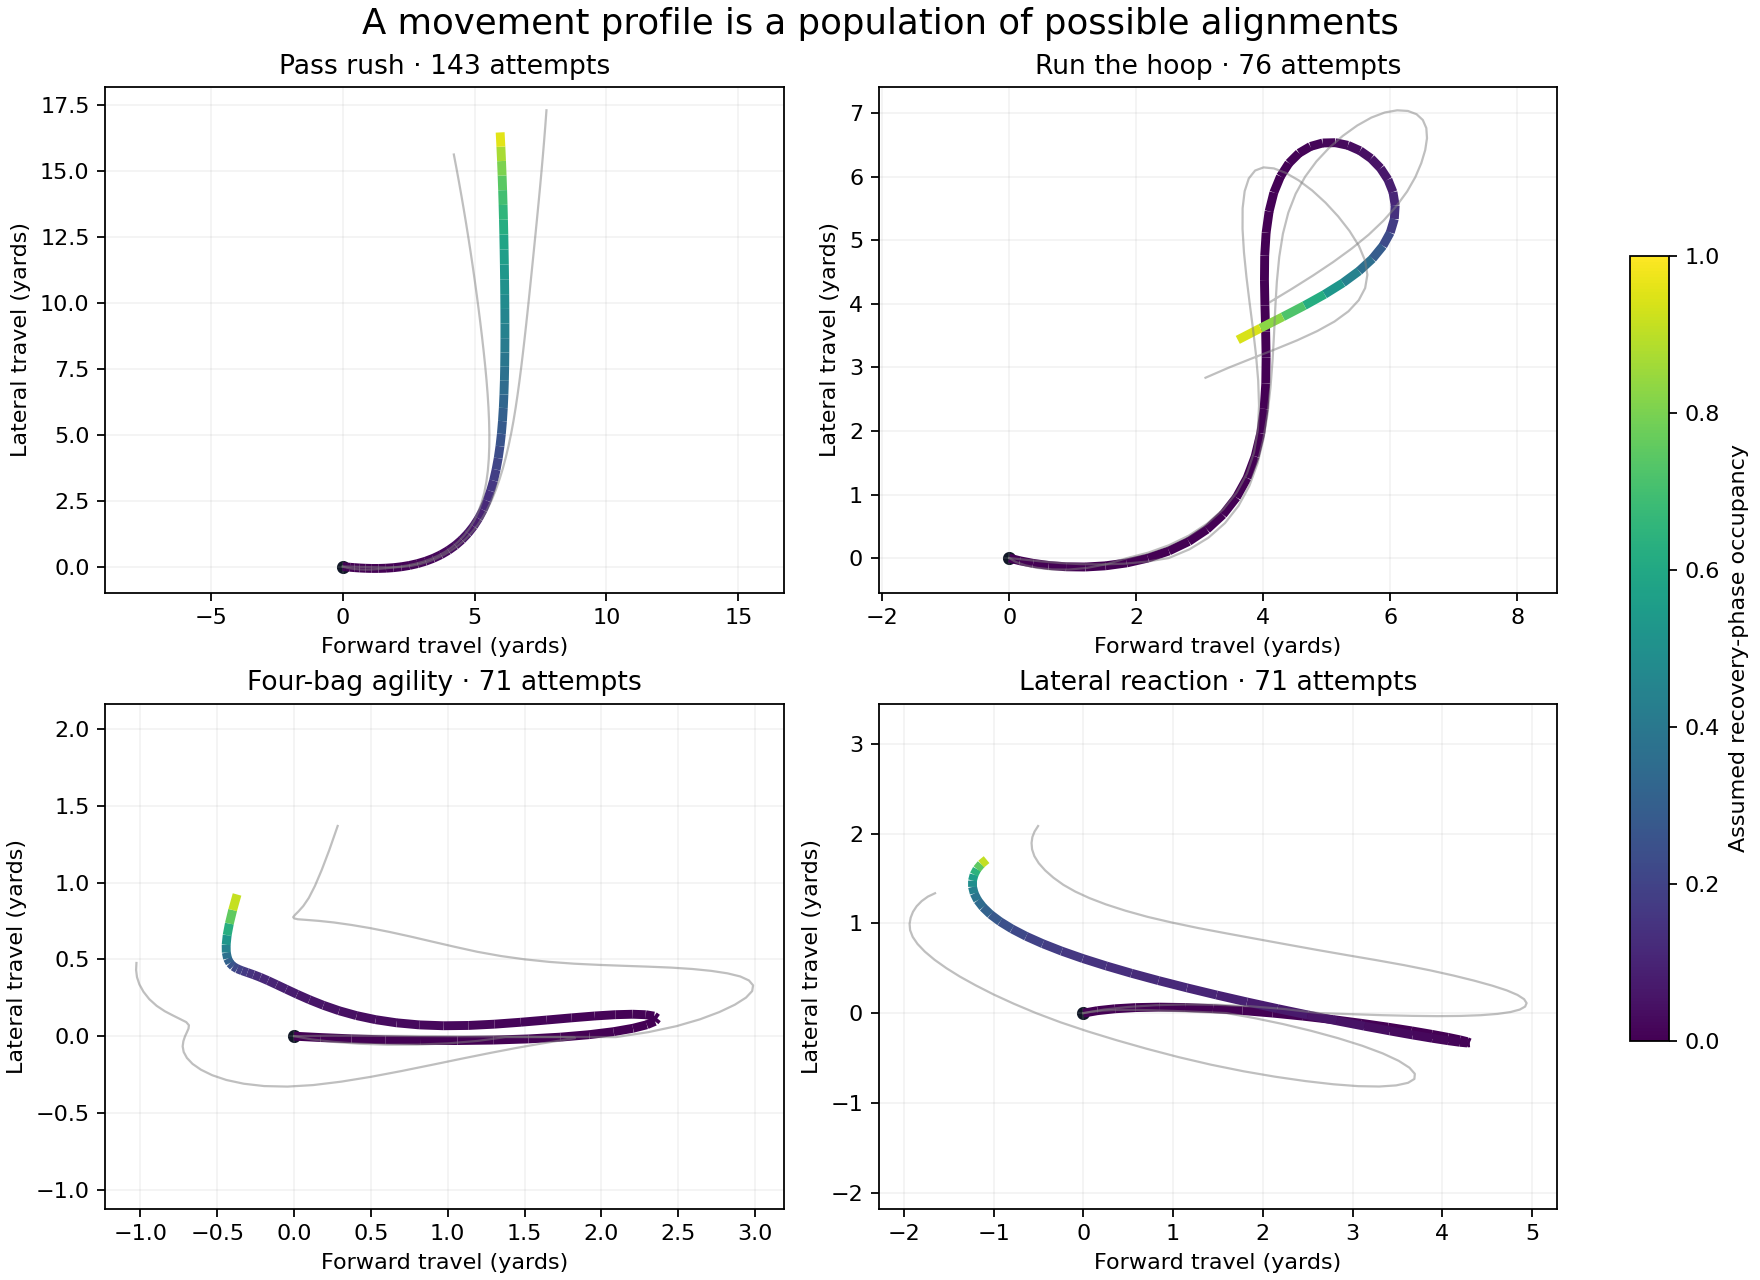

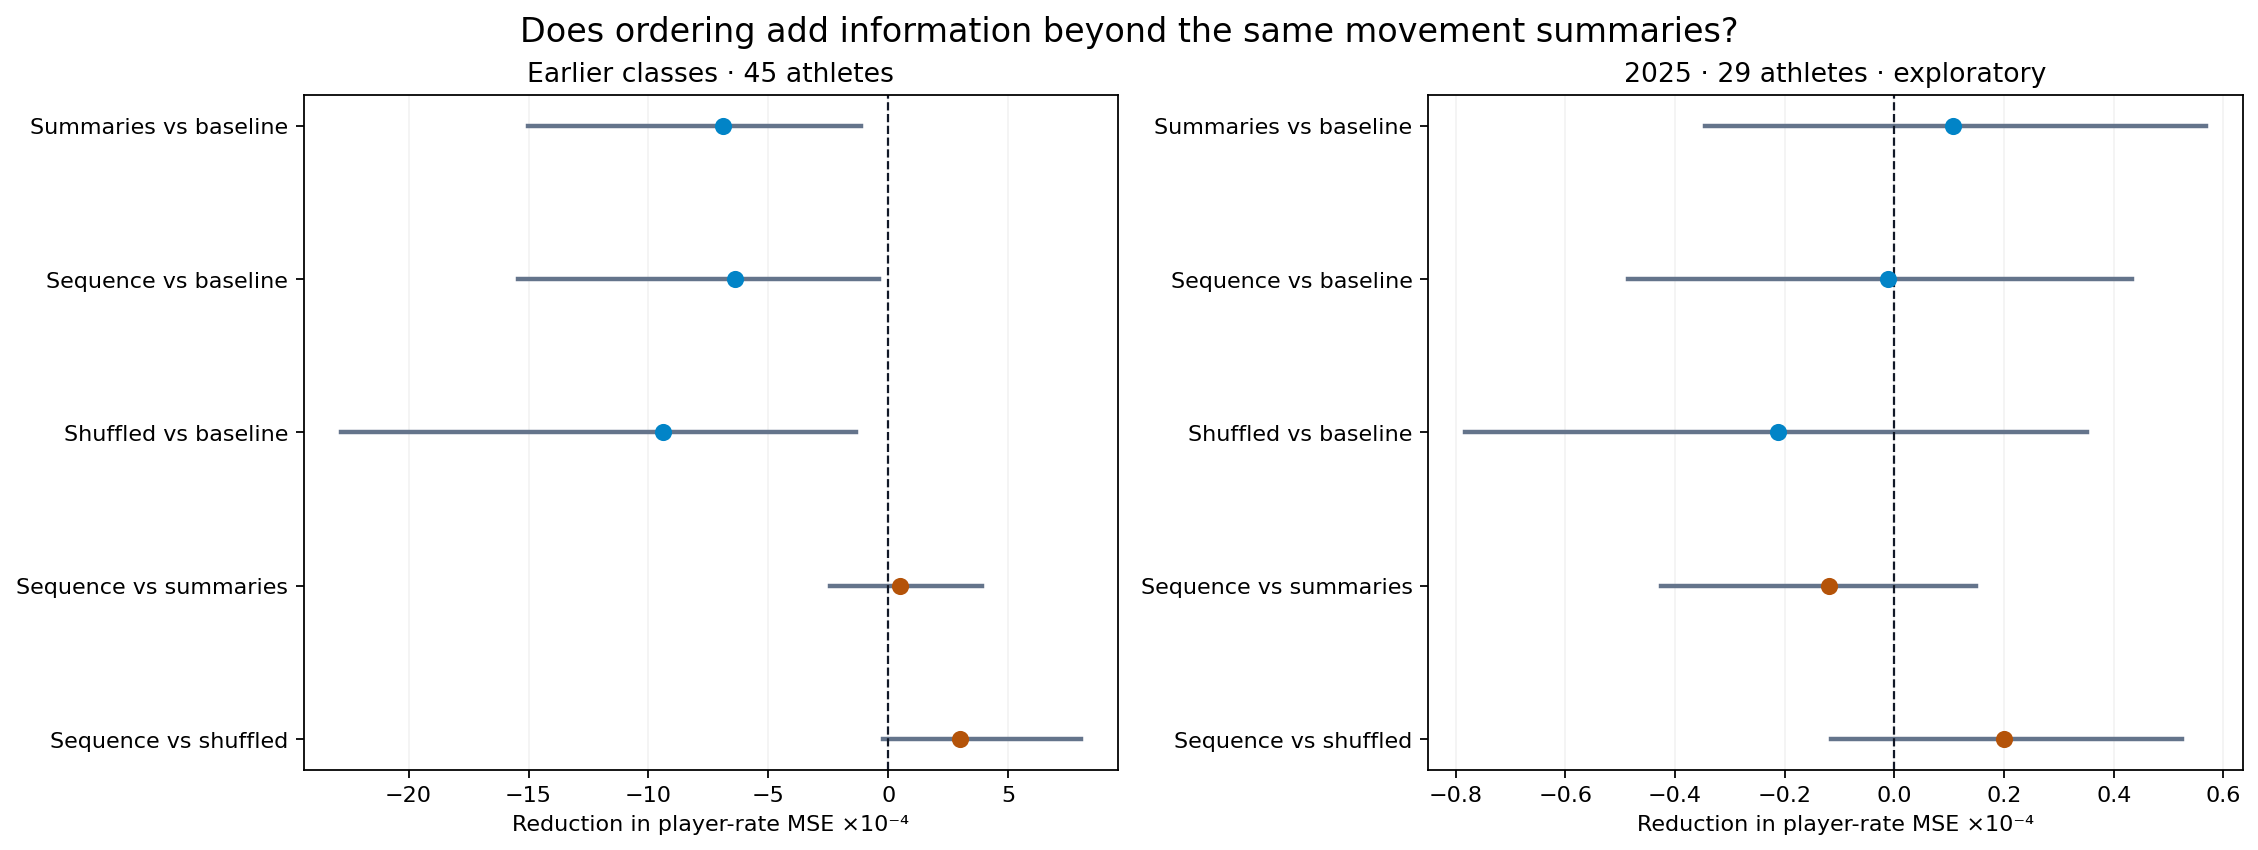

In [4]:
OUT=WORK/'receipts/phase_population';OUT.mkdir(parents=True,exist_ok=True)
V.geometry(DATA,OUT);V.results(OUT)
display(Image(filename=str(OUT/'phase_geometry.png')))
display(Image(filename=str(OUT/'phase_comparisons.png')))


## Adapt without replacing the benchmark

After the concatenation results were inspected, we locked a second experiment: retain the unchanged conventional ensemble and add a source-only correction. On each outer training set, three player-separated conventional ensembles supply out-of-fold residuals. Average residuals over each training player's actual workload. Fit a zero-intercept ridge with fixed alpha 100 to four physical-conditioned source components, their squares and mass interactions. Predict one correction per held-out athlete and clip final probabilities to [0,1]. All families receive the same residuals and shrinkage budget; zero source coefficients recover the exact baseline.

This is an adaptive follow-up, explicitly including knowledge of the first experiment's 2025 results. No correction hyperparameter is selected from these outcomes, and no new independent test class is created by changing the model. Player residualization changes the statistical target from individual rush fluctuations to persistent athlete calibration; it does not establish a causal movement effect.


Baseline-preserving correction nested {'conventional': 0.0009976460555967727, 'summaries': 0.0018139970742602593, 'sequence': 0.0015580348147615853, 'shuffled': 0.0016048152672989682}
conventional->sequence relative reduction: -56.17 %, delta 95% interval: [-0.0018696622923946456, 0.000332069192001587]
summaries->sequence relative reduction: 14.11 %, delta 95% interval: [-0.00014485051430933673, 0.0007556146755839207]
shuffled->sequence relative reduction: 2.92 %, delta 95% interval: [-0.00017203902873387742, 0.0002882633385611707]
Baseline-preserving correction exploratory_2025 {'conventional': 0.0005750755264042483, 'summaries': 0.0009111974468799254, 'sequence': 0.000959405557259169, 'shuffled': 0.0011184281610214437}
conventional->sequence relative reduction: -66.83 %, delta 95% interval: [-0.0009684329374856803, 4.345491058476012e-05]
summaries->sequence relative reduction: -5.29 %, delta 95% interval: [-0.0005303843508820848, 0.00039084445127210833]
shuffled->sequence relative re

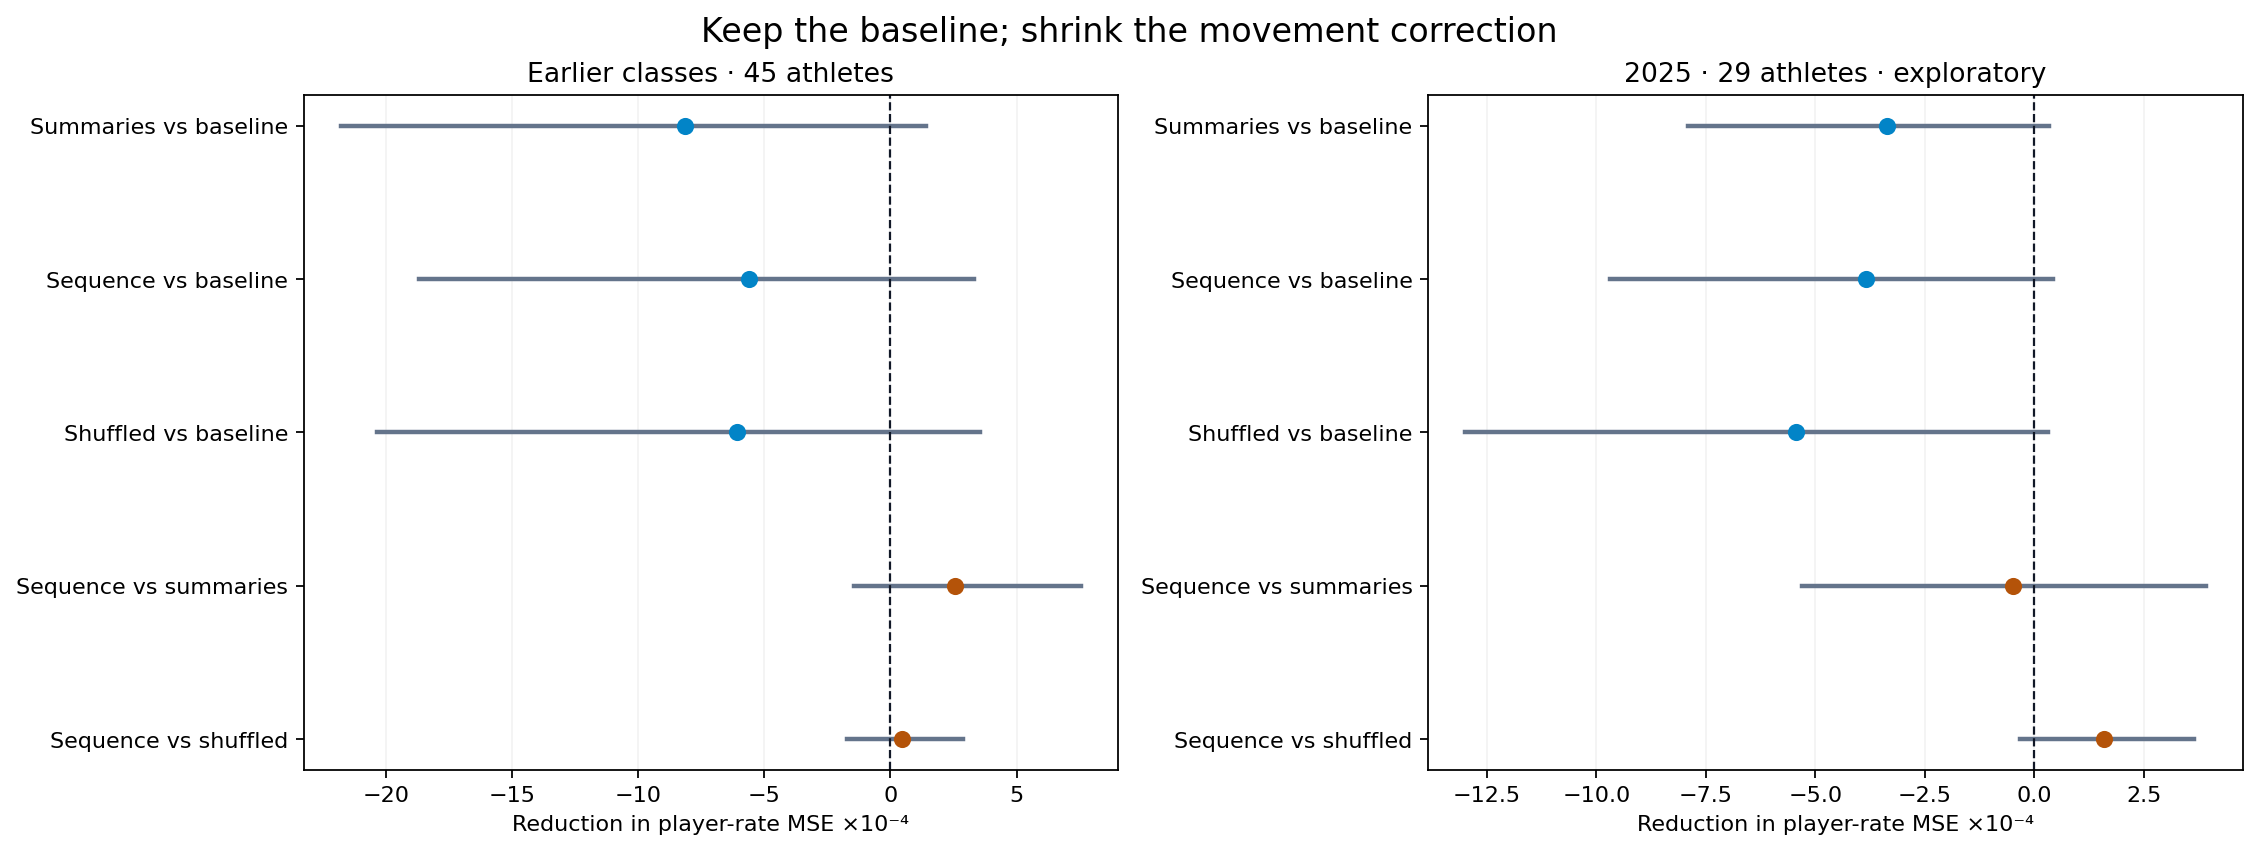

In [5]:
with (WORK/'phase_correction.log').open('w') as log,contextlib.redirect_stdout(log):corrected=C.run()
for split in ['nested','exploratory_2025']:
    print('Baseline-preserving correction',split,corrected[split]['player_rate_mse'])
    for key in ['conventional->sequence','summaries->sequence','shuffled->sequence']:
        c=corrected[split]['comparisons'][key]
        print(key,'relative reduction:',round(100*c['relative_reduction'],2),'%, delta 95% interval:',c['ci95'])
CORRECTED=OUT/'correction';CORRECTED.mkdir(exist_ok=True)
V.results(CORRECTED,'private_phase_correction',title='Keep the baseline; shrink the movement correction')
display(Image(filename=str(CORRECTED/'phase_comparisons.png')))


The first correction leaves nonlinear coordinates unscaled, so a single ridge penalty does not shrink squared components and mass interactions equally. Preserve that failed fit and test a further locked adaptation: clip each correction coordinate at its training 1st/99th percentiles, then standardize using training players before the same zero-intercept ridge. Reuse the exact baseline residuals and compare all three source families. This is numerical conditioning and an empirical support restriction, not a calibrated measurement-error model. It was designed after seeing the first correction and therefore remains adaptive exploratory work.


Scaled, support-limited correction nested {'conventional': 0.0009976460555967727, 'summaries': 0.0010453502604265573, 'sequence': 0.000992448662347204, 'shuffled': 0.0009976500567600982}
conventional->sequence relative reduction: 0.52 %, delta 95% interval: [-6.370803023806915e-05, 8.019255924811569e-05]
summaries->sequence relative reduction: 5.06 %, delta 95% interval: [2.695731834913015e-06, 0.00012061181493084304]
shuffled->sequence relative reduction: 0.52 %, delta 95% interval: [-2.445545564835075e-05, 3.353954982495032e-05]
Scaled, support-limited correction exploratory_2025 {'conventional': 0.0005750755264042483, 'summaries': 0.0005168628452388616, 'sequence': 0.0005721766835417392, 'shuffled': 0.0005819629071490008}
conventional->sequence relative reduction: 0.5 %, delta 95% interval: [-5.7213935550440864e-05, 5.121240789197777e-05]
summaries->sequence relative reduction: -10.7 %, delta 95% interval: [-0.0001241711957054252, -9.193820969969722e-06]
shuffled->sequence relative 

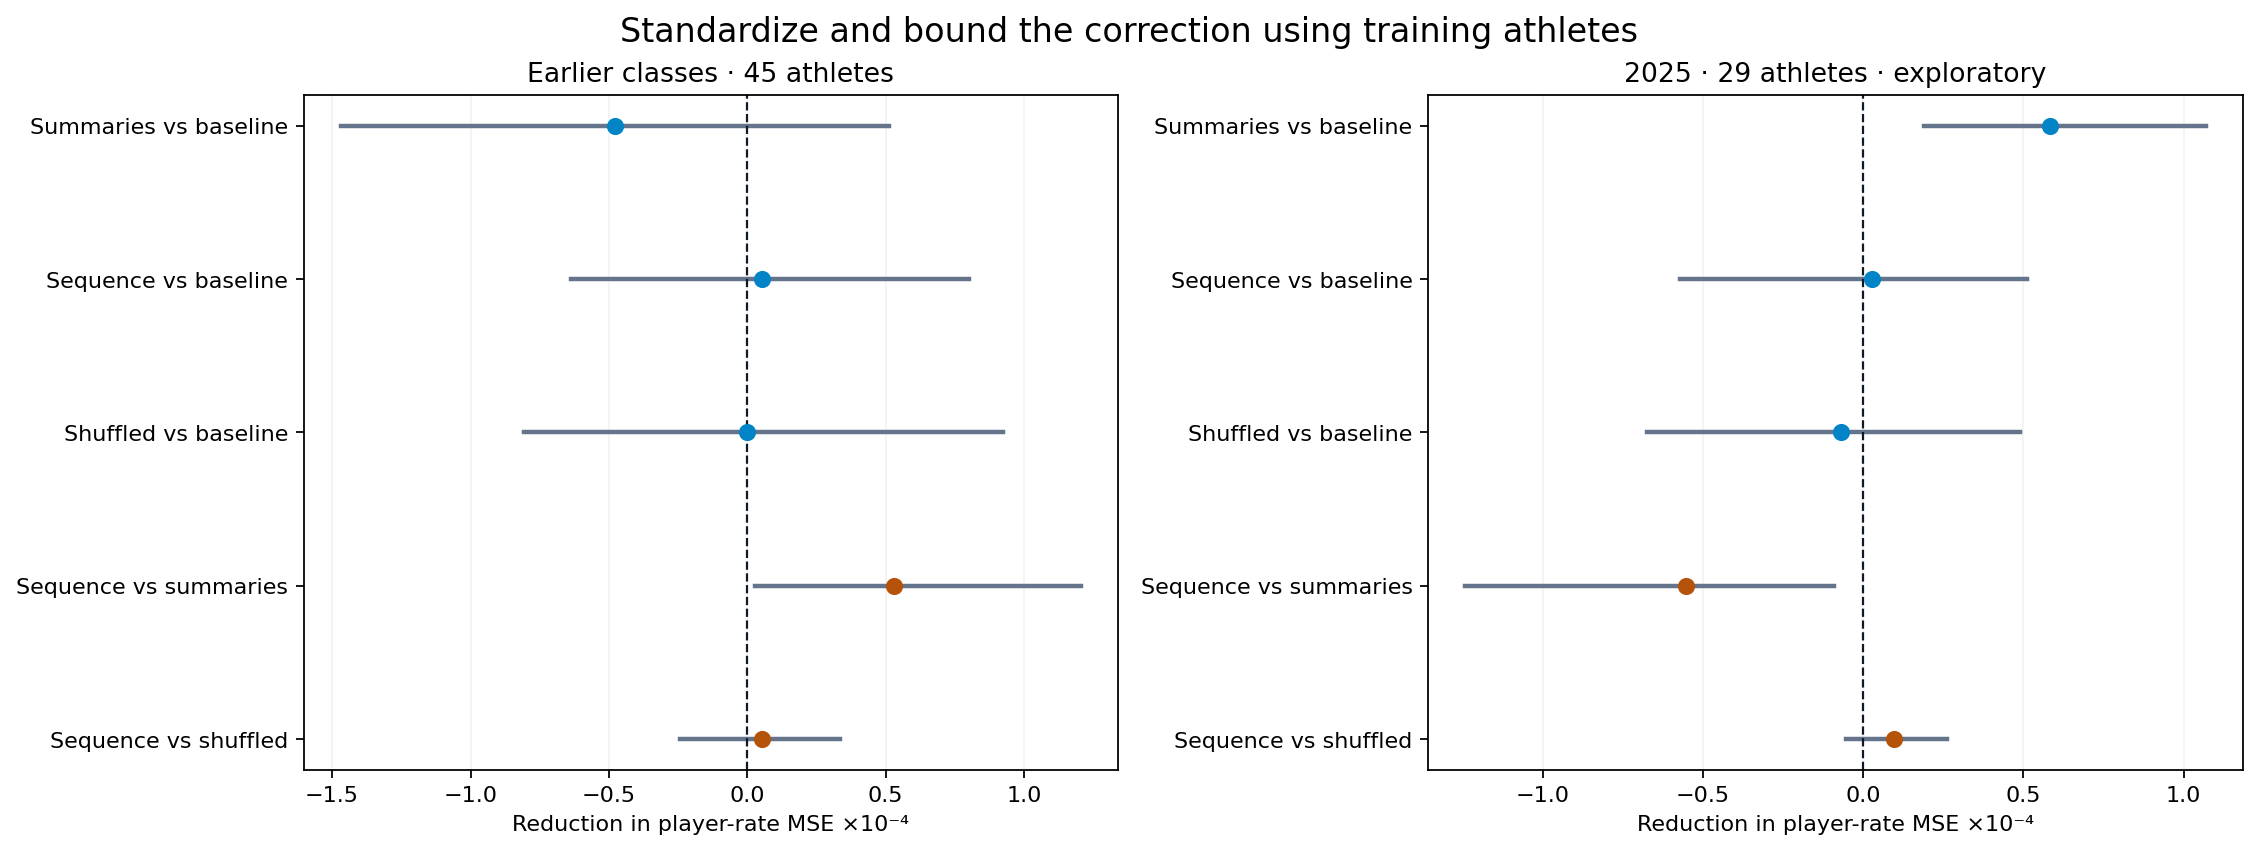

In [6]:
with (WORK/'phase_scaled_correction.log').open('w') as log,contextlib.redirect_stdout(log):scaled=C.run('private_phase_correction_scaled',scaled=True)
for split in ['nested','exploratory_2025']:
    print('Scaled, support-limited correction',split,scaled[split]['player_rate_mse'])
    for key in ['conventional->sequence','summaries->sequence','shuffled->sequence']:
        c=scaled[split]['comparisons'][key]
        print(key,'relative reduction:',round(100*c['relative_reduction'],2),'%, delta 95% interval:',c['ci95'])
SCALED=OUT/'scaled';SCALED.mkdir(exist_ok=True)
V.results(SCALED,'private_phase_correction_scaled',title='Standardize and bound the correction using training athletes')
display(Image(filename=str(SCALED/'phase_comparisons.png')))


## Read the test as evidence

Positive reductions mean smaller prediction error, not more pressures produced. If ordering does not improve on ordinary summaries, the proposed PerfectPower linkage is unsupported by this test. If sequence features perform well only on earlier classes, transport remains unresolved. If shuffled features match or improve on the sequence family, do not attribute any source gain specifically to movement order.

A development protocol would require validated semantic phase labels, repeatability across attempts, and independent prospects or classes. These data can generate a candidate movement signal, but a causal coaching intervention or reliable hidden-talent ranking needs additional evidence. We retain all families and their uncertainty regardless of which is best.
